# Dastgāh — setar / oud / kemancheh / ney pitch starter

Download with [muget](https://github.com/meikoy-chan/muget), analyze with [audioFlux](https://github.com/libAudioFlux/audioFlux).

**Env:** `micromamba activate freqs` · needs `ffmpeg` (+ `deno` for yt-dlp).


In [221]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import matplotlib.pyplot as plt

import audioflux as af
from audioflux.display import fill_spec, fill_wave

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
AUDIO_DIR = ROOT / "audio"
ANALYSIS_DIR = ROOT / "analysis"
AUDIO_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

# --- cache switches (Run All stays cheap unless you flip these) ---
FORCE_DOWNLOAD = False          # re-fetch YouTube even if audio exists
FORCE_WAV = False               # re-ffmpeg even if .wav is newer than .m4a
FORCE_REBUILD_CONSENSUS = False # recompute consensus from strikes_*.npz

print("python:", sys.executable)
print("audioflux:", getattr(af, "__version__", af))
print("audio dir:", AUDIO_DIR)
print("analysis:", ANALYSIS_DIR)
print(f"FORCE_DOWNLOAD={FORCE_DOWNLOAD}  FORCE_WAV={FORCE_WAV}  FORCE_REBUILD_CONSENSUS={FORCE_REBUILD_CONSENSUS}")


python: /Users/ed/micromamba/envs/freqs/bin/python
audioflux: 0.1.9
audio dir: /Users/ed/Developer/dastgaah/audio
analysis: /Users/ed/Developer/dastgaah/analysis
FORCE_DOWNLOAD=False  FORCE_WAV=False  FORCE_REBUILD_CONSENSUS=False


## 1. Sources

| key | artist | piece | url |
|---|---|---|---|
| `shekarchi_mahour` | Aliakbar Shekarchi (kemancheh) | **full album** *Radif Of Persian Classical Music / Dastgahe Mahour* (33 tracks) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_mwXelFN3KZjgXparnoANiR7xuGEmAPC4w) |
| `lotfi_darvish` | Mohammad Reza Lotfi | *In the Memory of Darvish Khan* (2006 CD) — **use first 20 min** (retunes ~30m) | [link](https://www.youtube.com/watch?v=M5OQyDJZybs) |
| `lotfi_mahur_pl` | Mohammad Reza Lotfi | curated Mahur guшеhs from mixed playlist (skip songs/Dashti/etc.) | [playlist](https://www.youtube.com/playlist?list=PLQp0EnRwwR1eJdcUqgAXgVMq3D0ysgH2W) |
| `ebadi_mahur` | Ahmad Ebadi (setar) | *Setar Solo* — **Mahur only** (~11.5 min continuous; skip other dastgahs in playlist) | [link](https://www.youtube.com/watch?v=A9S5UGMcrkU) |
| `saba_mahoor` | Abolhasan Saba (setar) | *Setar by Saba* — continuous **Mahoor** (~17 min) | [link](https://www.youtube.com/watch?v=is3aQMwHKto) |
| `karimi_mahur` | Mahmud Karimi (voice) | *Avaz Course: Vocal Radif Vol. 3* — **Mahur only** (tracks 11–30; skip Chahargah/Rast-Panjgah) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_m4dCFMnjQWeftOYFJ5gTkk7flPWpkbA4w) |
| `kasaei_radif` | Hassan Kasaei (setar) | *Iranian Classical Music Radifs 1* — **Mahoor only** (tracks 1–43; skip Shur) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_kombsv6vIFDKsGMN4lgrLVU7A__TbZQYs) |
| `shahnazi_mahur` | Ali-Akbar Shahnazi (tar) | *The Advanced Shahnazi Radif III* — **Mahur only** (tracks 1–23; skip Homayun) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_kp6IaJ5pCmOujPZaaIcVVM25OOnDxsgig) |
| `neydavud_mahur` | Morteza Neydavud (tar) | *Radif of Persian Music on Tar, Vol. 4* — Mahur (quality/Do filtered; noisy transfer) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_m24pG0giA7K1Zp4f-YZkZbYIJJ8o2qATE) |
| `forutan_mahur` | Yusef Forutan (setar) | *Radif of Persian Music on Setar III* — **Mahur only** (tracks 1–14; skip Afshari/Esfahan/Nava) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_n89lv4AxI3_B7mklDEtXRPr5n9PgJMAiU) |
| `borumand_mahur` | Nur-Ali Borumand (tar/setar) | **full album** *Mirza Abdollah Radif Vol. 6 — Mahur* (44 tracks) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_kWQ7sKi51ALkgSZrpRs3CsSSMJPqf7awg) |
| `alizadeh_mahur` | Hossein Alizadeh (setar) | **full album** *Radif Navazi - Setar: Mahur* (36 tracks) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_l3CKW4Hxd3D93TVXsg2m1BEGWAk9dNXa4) |
| `alizadeh_avaz` | Hossein Alizadeh (setar) | Mahur: Avaz | [link](https://www.youtube.com/watch?v=eoQ4l3cmVAE) |
| `alizadeh_moghadameh` | Hossein Alizadeh (setar) | Mahur: Moghadameh-e Dad | [link](https://www.youtube.com/watch?v=QYiitn_5ig0) |
| `nariman_mahour` | Mansour Nariman (oud) | **full album** *Iranian Music Radif for Oud / Dastgahe Mahour* (20 tracks) | [playlist](https://www.youtube.com/playlist?list=OLAK5uy_mOPYIjrf1BW6NGV-reUsBqBZa-isHdNsU) |
| `nariman_moghadame` | Mansour Nariman (oud) | track 1 — Moghadame | [link](https://www.youtube.com/watch?v=wJqrcpxIsnE) |
| `nariman_bardasht` | Mansour Nariman (oud) | track 2 — Bardasht | [link](https://www.youtube.com/watch?v=Imoxx03KFb8) |

Skip the download cell if files are already under `audio/`.


In [222]:
TRACKS = {
    "alizadeh_avaz": "https://www.youtube.com/watch?v=eoQ4l3cmVAE",
    "alizadeh_moghadameh": "https://www.youtube.com/watch?v=QYiitn_5ig0",
    "nariman_moghadame": "https://www.youtube.com/watch?v=wJqrcpxIsnE",
    "nariman_bardasht": "https://www.youtube.com/watch?v=Imoxx03KFb8",
    # full albums / sources (already cached under audio/YouTube Music/…)
    "nariman_mahour": "https://www.youtube.com/playlist?list=OLAK5uy_mOPYIjrf1BW6NGV-reUsBqBZa-isHdNsU",
    "alizadeh_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_l3CKW4Hxd3D93TVXsg2m1BEGWAk9dNXa4",
    "shekarchi_mahour": "https://www.youtube.com/playlist?list=OLAK5uy_mwXelFN3KZjgXparnoANiR7xuGEmAPC4w",
    "lotfi_darvish": "https://www.youtube.com/watch?v=M5OQyDJZybs",
    "borumand_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_kWQ7sKi51ALkgSZrpRs3CsSSMJPqf7awg",
    "lotfi_mahur_pl": "https://www.youtube.com/playlist?list=PLQp0EnRwwR1eJdcUqgAXgVMq3D0ysgH2W",
    "forutan_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_n89lv4AxI3_B7mklDEtXRPr5n9PgJMAiU",
    "neydavud_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_m24pG0giA7K1Zp4f-YZkZbYIJJ8o2qATE",
    "shahnazi_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_kp6IaJ5pCmOujPZaaIcVVM25OOnDxsgig",
    "kasaei_radif": "https://www.youtube.com/playlist?list=OLAK5uy_kombsv6vIFDKsGMN4lgrLVU7A__TbZQYs",
    "karimi_mahur": "https://www.youtube.com/playlist?list=OLAK5uy_m4dCFMnjQWeftOYFJ5gTkk7flPWpkbA4w",
    "saba_mahoor": "https://www.youtube.com/watch?v=is3aQMwHKto",
    "ebadi_mahur": "https://www.youtube.com/watch?v=A9S5UGMcrkU",
}

# Presence checks — skip network if audio already on disk
def _has_wavs(subglob: str, min_n: int = 1) -> bool:
    hits = list((AUDIO_DIR / "YouTube Music").glob(subglob))
    return len(hits) >= min_n

CACHED = {
    "nariman_mahour": _has_wavs("Mansour Nariman/**/*.wav", 15),
    "alizadeh_mahur": _has_wavs("Hossein Alizadeh/**/*.wav", 30),
    "shekarchi_mahour": _has_wavs("Aliakbar Shekarchi/**/*.wav", 25),
    "borumand_mahur": _has_wavs("Nur-Ali Borumand/**/*.wav", 30),
    "forutan_mahur": _has_wavs("Yusef Forutan/**/*.wav", 10),
    "neydavud_mahur": _has_wavs("Morteza Neydavud/**/*.wav", 15),
    "shahnazi_mahur": _has_wavs("Ali-Akbar Shahnazi/The Advanced*/**/*.wav", 10), 1),
    "kasaei_radif": _has_wavs("Hassan Kasaei/Iranian Classical*/**/*.wav", 20),
    "karimi_mahur": _has_wavs("Mahmud Karimi/**/*.wav", 10),
    "saba_mahoor": _has_wavs("Abolhasan Saba/**/*.wav", 1),
    "lotfi_darvish": _has_wavs("Mohammad Reza Lotfi/In the Memory*/**/*.wav", 1),
    "lotfi_mahur_pl": _has_wavs("Mohammad Reza Lotfi/Mahur playlist*/**/*.wav", 5),
    "ebadi_mahur": _has_wavs("Ahmad Ebadi/**/*.wav", 1),
}

DOWNLOAD = []  # empty = use cache; set keys (or FORCE_DOWNLOAD) to fetch
if FORCE_DOWNLOAD:
    DOWNLOAD = ["nariman_mahour", "alizadeh_mahur", "shekarchi_mahour"]

for key in DOWNLOAD:
    if CACHED.get(key) and not FORCE_DOWNLOAD:
        print(f"skip download (cached): {key}")
        continue
    cmd = [
        "muget", "-n",
        "-o", str(AUDIO_DIR),
        "--audio-itag", "140",
        "--no-save-cover",
        TRACKS[key],
    ]
    print(" ".join(cmd))
    subprocess.run(cmd, check=False)

print("audio cache:")
for k, ok in CACHED.items():
    print(f"  {'✓' if ok else '·'} {k}")

# muget sometimes writes under CWD/YouTube Music — fold into audio/
for stray in (ROOT / "YouTube Music", ROOT / "notebooks" / "YouTube Music"):
    if stray.is_dir():
        dest = AUDIO_DIR / "YouTube Music"
        dest.mkdir(parents=True, exist_ok=True)
        subprocess.run(["rsync", "-a", f"{stray}/", f"{dest}/"], check=True)
        subprocess.run(["rm", "-rf", str(stray)], check=True)
        print("merged stray →", dest)

# Convert any new m4a → wav (skipped if wav newer, unless FORCE_WAV)
n_new = 0
for m4a in sorted(AUDIO_DIR.rglob("*.m4a")):
    wav = m4a.with_suffix(".wav")
    if (not FORCE_WAV) and wav.exists() and wav.stat().st_mtime >= m4a.stat().st_mtime:
        continue
    subprocess.run(
        ["ffmpeg", "-y", "-i", str(m4a), "-ac", "1", str(wav)],
        check=True, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL,
    )
    n_new += 1
    print("wav:", wav.relative_to(AUDIO_DIR))
print(f"wav convert: {n_new} new, rest cached")


SyntaxError: closing parenthesis ')' does not match opening parenthesis '{' on line 26 (2654265048.py, line 33)

In [ ]:
AUDIO_EXTS = {".opus", ".m4a", ".mp3", ".wav", ".flac", ".ogg"}
tracks = sorted(
    p for p in AUDIO_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in AUDIO_EXTS
)
for i, p in enumerate(tracks):
    print(f"[{i}] {p.relative_to(AUDIO_DIR)}")

assert tracks, f"No audio under {AUDIO_DIR}"

# Pick piece: "Moghadame", "Bardasht", "Avaz", "Moghadameh", ...
SELECT = "Bardasht"  # track 2; use "Moghadame" for track 1
ARTIST = "Nariman"  # or "Alizadeh", or "" for either

candidates = [
    p for p in tracks
    if SELECT.lower() in p.name.lower()
    and (not ARTIST or ARTIST.lower() in str(p).lower())
] or tracks
AUDIO_PATH = next((p for p in candidates if p.suffix.lower() == ".wav"), candidates[0])
print("SELECT =", SELECT, " ARTIST =", ARTIST or "(any)")
print("using:", AUDIO_PATH)


[0] YouTube Music/Hossein Alizadeh/Radif Navazi - Setar_ Mahur/03 - Mahur_ Avaz.m4a
[1] YouTube Music/Hossein Alizadeh/Radif Navazi - Setar_ Mahur/03 - Mahur_ Avaz.wav
[2] YouTube Music/Hossein Alizadeh/Radif Navazi - Setar_ Mahur/04 - Mahur_ Moghadameh-e Dad.m4a
[3] YouTube Music/Hossein Alizadeh/Radif Navazi - Setar_ Mahur/04 - Mahur_ Moghadameh-e Dad.wav
[4] YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/01 - Dastgahe Mahour _ Moghadame.m4a
[5] YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/01 - Dastgahe Mahour _ Moghadame.wav
[6] YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/02 - Goosheye Bardasht.m4a
[7] YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/02 - Goosheye Bardasht.wav
SELECT = Bardasht  ARTIST = Nariman
using: /Users/ed/Developer/dastgaah/audio/YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/02 - Goosheye Bardasht.wav


## 2. Load waveform

`soundfile` cannot read `.m4a` — convert to WAV with `ffmpeg` first (cached beside the original).

sr=44100 Hz  samples=3726784  duration=84.5s


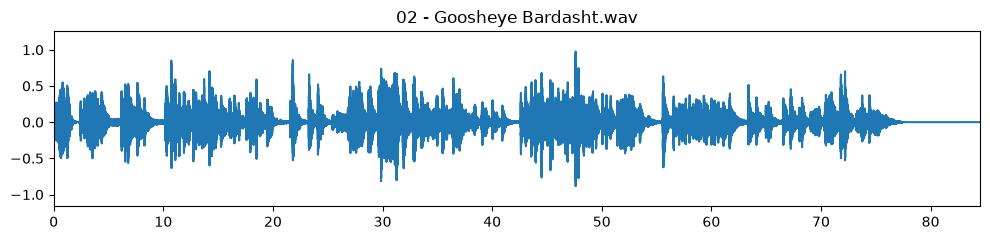

In [ ]:
NEED_CONVERT = {".m4a", ".mp3", ".opus", ".ogg", ".webm", ".aac"}


def ensure_wav(path: Path) -> Path:
    if path.suffix.lower() == ".wav":
        return path
    if path.suffix.lower() not in NEED_CONVERT:
        return path
    wav_path = path.with_suffix(".wav")
    if not wav_path.exists() or wav_path.stat().st_mtime < path.stat().st_mtime:
        subprocess.run(
            ["ffmpeg", "-y", "-i", str(path), "-ac", "1", str(wav_path)],
            check=True,
            capture_output=True,
        )
        print("converted ->", wav_path)
    return wav_path


WAV_PATH = ensure_wav(AUDIO_PATH)
audio, sr = af.read(str(WAV_PATH))
if audio.ndim > 1:
    audio = np.mean(audio, axis=0)

duration = audio.shape[-1] / sr
print(f"sr={sr} Hz  samples={audio.shape[-1]}  duration={duration:.1f}s")

fig, ax = plt.subplots(figsize=(10, 2.5))
fill_wave(audio, samplate=sr, axes=ax)
ax.set_title(AUDIO_PATH.name)
plt.tight_layout()
plt.show()

## 3. Mel spectrogram (narrow band)

Energy for these openings sits mostly ~100–500 Hz + a few harmonics → limit Mel to **80–2000 Hz**, plot in dB.

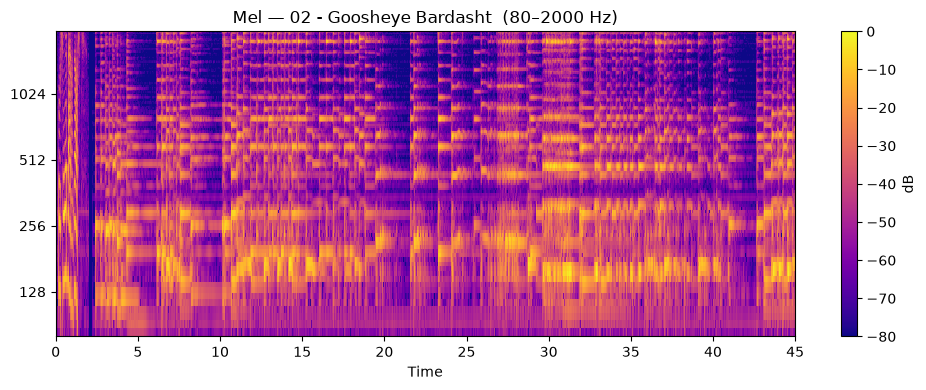

In [ ]:
MAX_SECONDS = 45  # Moghadameh-e Dad is short; Nariman opening is longer
clip = audio[..., : int(min(MAX_SECONDS, duration) * sr)]

FMIN_MEL, FMAX_MEL = 80.0, 2000.0

spec, mel_fre = af.mel_spectrogram(
    clip,
    num=128,
    radix2_exp=12,
    samplate=sr,
    low_fre=FMIN_MEL,
    high_fre=FMAX_MEL,
)
spec_db = af.utils.power_to_db(np.abs(spec))

x_coords = np.linspace(0, clip.shape[-1] / sr, spec_db.shape[-1] + 1)
y_coords = np.insert(mel_fre, 0, FMIN_MEL)

fig, ax = plt.subplots(figsize=(10, 4))
img = fill_spec(
    spec_db, axes=ax,
    x_coords=x_coords, y_coords=y_coords,
    x_axis="time", y_axis="log",
    title=f"Mel — {AUDIO_PATH.stem}  ({FMIN_MEL:.0f}–{FMAX_MEL:.0f} Hz)",
)
fig.colorbar(img, ax=ax, label="dB")
plt.tight_layout()
plt.show()

## 4. Pitch (F0) — HPS

YIN tends to hug a low spurious floor on plucked strings. **HPS** tracks ~200–500 Hz fundamentals more reliably.  
`PitchHPS.pitch()` returns a **single** array (not a YIN-style tuple).

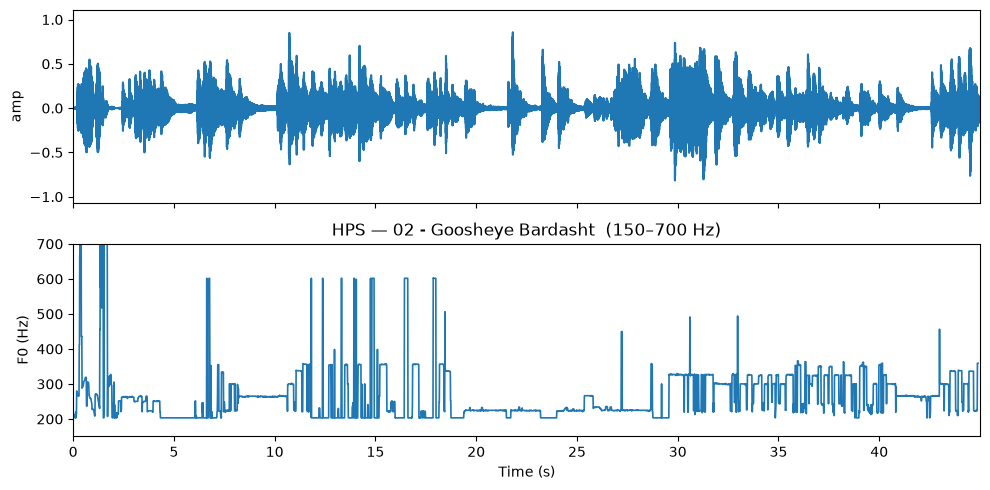

F0 median=244.9 Hz  p10=203.2  p90=337.8


In [ ]:
FMIN, FMAX = 150.0, 700.0

pitcher = af.PitchHPS(
    samplate=sr,
    low_fre=FMIN,
    high_fre=FMAX,
    slide_length=512,
    harmonic_count=5,
)
fre_arr = np.asarray(
    pitcher.pitch(np.ascontiguousarray(clip, dtype=np.float32)),
    dtype=float,
).copy()
fre_arr[fre_arr < 1] = np.nan

times = np.arange(fre_arr.shape[-1]) * (pitcher.slide_length / pitcher.samplate)

fig, axes = plt.subplots(nrows=2, figsize=(10, 5), sharex=True)
fill_wave(clip, samplate=sr, axes=axes[0])
axes[0].set_ylabel("amp")

axes[1].plot(times, fre_arr, linewidth=1.2)
axes[1].set_ylim(FMIN, FMAX)
axes[1].set_ylabel("F0 (Hz)")
axes[1].set_xlabel("Time (s)")
axes[1].set_title(f"HPS — {AUDIO_PATH.stem}  ({FMIN:.0f}–{FMAX:.0f} Hz)")
plt.tight_layout()
plt.show()

valid = fre_arr[np.isfinite(fre_arr)]
if valid.size:
    print(
        f"F0 median={np.median(valid):.1f} Hz  "
        f"p10={np.percentile(valid, 10):.1f}  p90={np.percentile(valid, 90):.1f}"
    )

## 5. Compare Moghadameh — Alizadeh (setar) vs Nariman (oud)

- YouTube Music/Hossein Alizadeh/Radif Navazi - Setar_ Mahur/04 - Mahur_ Moghadameh-e Dad.wav
- YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/01 - Dastgahe Mahour _ Moghadame.wav


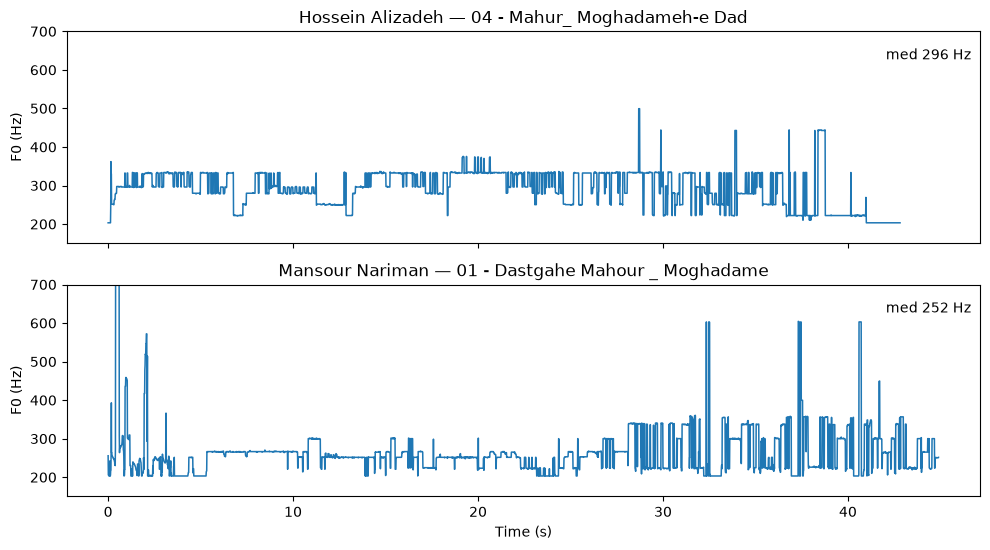

In [ ]:
def load_mono(path: Path):
    wav = ensure_wav(path)
    x, srate = af.read(str(wav))
    if x.ndim > 1:
        x = np.mean(x, axis=0)
    return x, srate


def hps_f0(x, srate, fmin=150.0, fmax=700.0, max_seconds=45):
    x = x[..., : int(max_seconds * srate)]
    pitcher = af.PitchHPS(
        samplate=srate, low_fre=fmin, high_fre=fmax,
        slide_length=512, harmonic_count=5,
    )
    fre = np.asarray(
        pitcher.pitch(np.ascontiguousarray(x, dtype=np.float32)),
        dtype=float,
    ).copy()
    fre[fre < 1] = np.nan
    t = np.arange(fre.shape[-1]) * (pitcher.slide_length / pitcher.samplate)
    return t, fre, x, srate


mogh = sorted(p for p in AUDIO_DIR.rglob("*.wav") if "moghadame" in p.name.lower())
assert len(mogh) >= 2, f"Need both Moghadameh WAVs, found: {mogh}"
for w in mogh:
    print("-", w.relative_to(AUDIO_DIR))

fig, axes = plt.subplots(nrows=len(mogh), figsize=(10, 2.8 * len(mogh)), sharex=True, sharey=True)
if len(mogh) == 1:
    axes = [axes]

for ax, path in zip(axes, mogh):
    x, srate = load_mono(path)
    t, fre, _, _ = hps_f0(x, srate)
    ax.plot(t, fre, linewidth=1.1)
    ax.set_ylim(150, 700)
    ax.set_ylabel("F0 (Hz)")
    label = path.parent.parent.name + " — " + path.stem
    ax.set_title(label)
    v = fre[np.isfinite(fre)]
    if v.size:
        ax.text(
            0.99, 0.92,
            f"med {np.median(v):.0f} Hz",
            transform=ax.transAxes, ha="right", va="top", fontsize=10,
        )
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## 7. Isolate notes — Nariman *Moghadame* (oud)

Focus on the opening (~0–12 s). Detect onsets from Mel-flux novelty, keep a few strong well-spaced attacks, then zoom each note: waveform, FFT spectrum, Mel, and HPS F0.


source: YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/01 - Dastgahe Mahour _ Moghadame.wav
isolated notes (s): [(0.168, 0.718), (2.943, 3.493), (5.364, 5.914), (6.966, 7.516)]


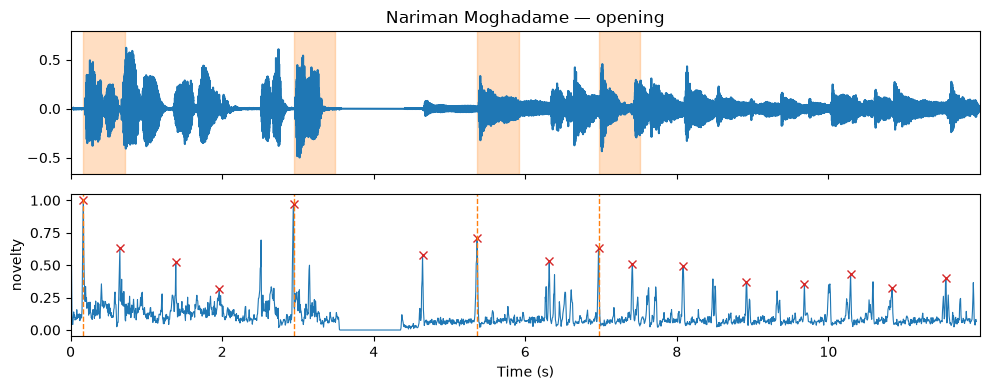

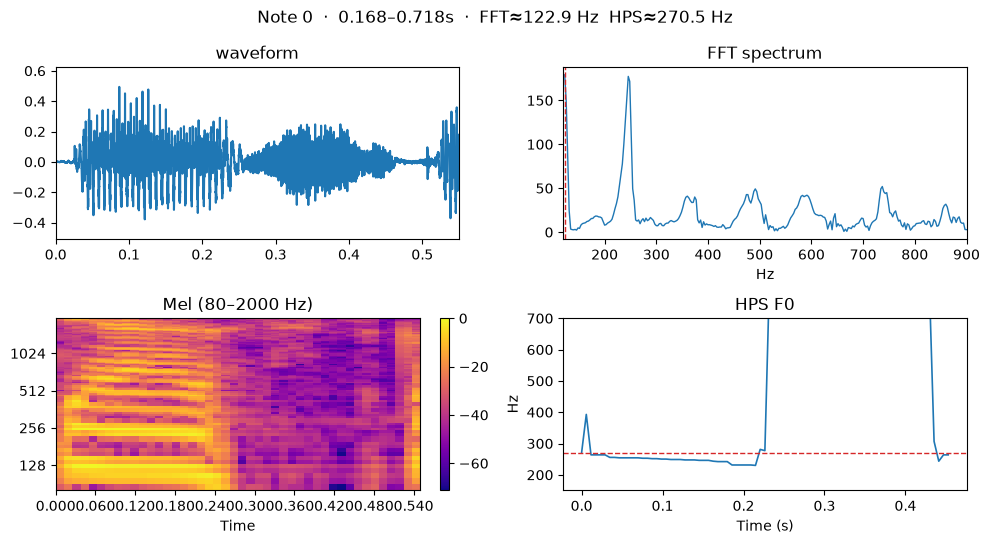

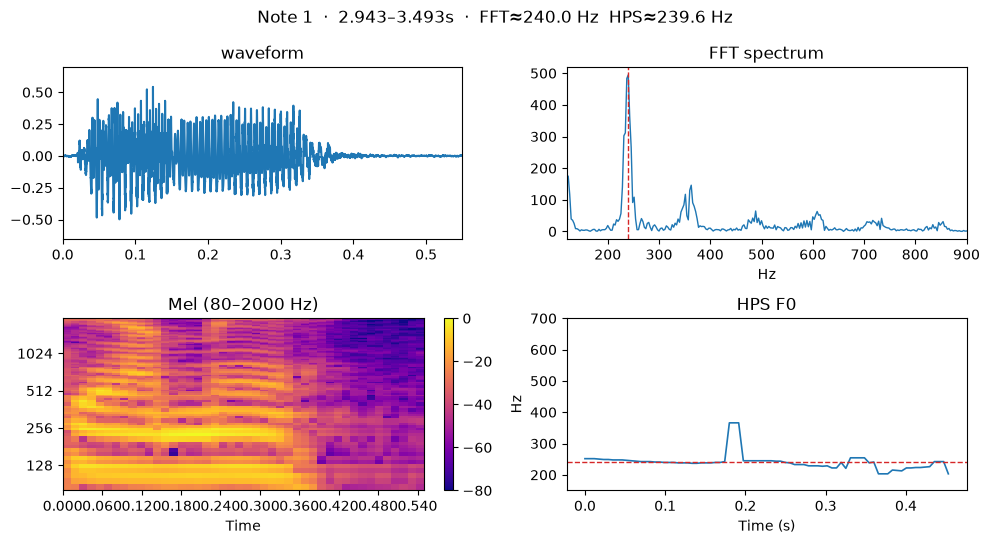

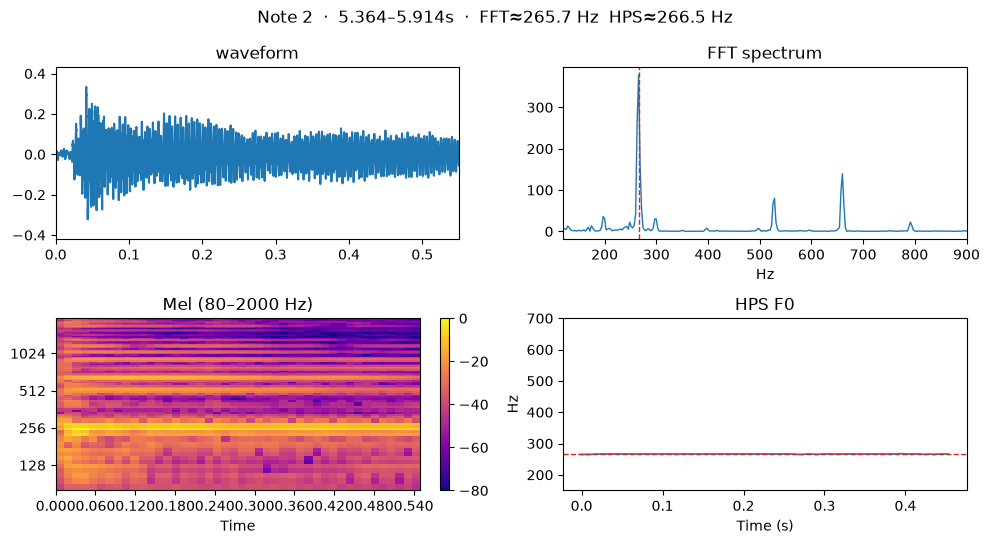

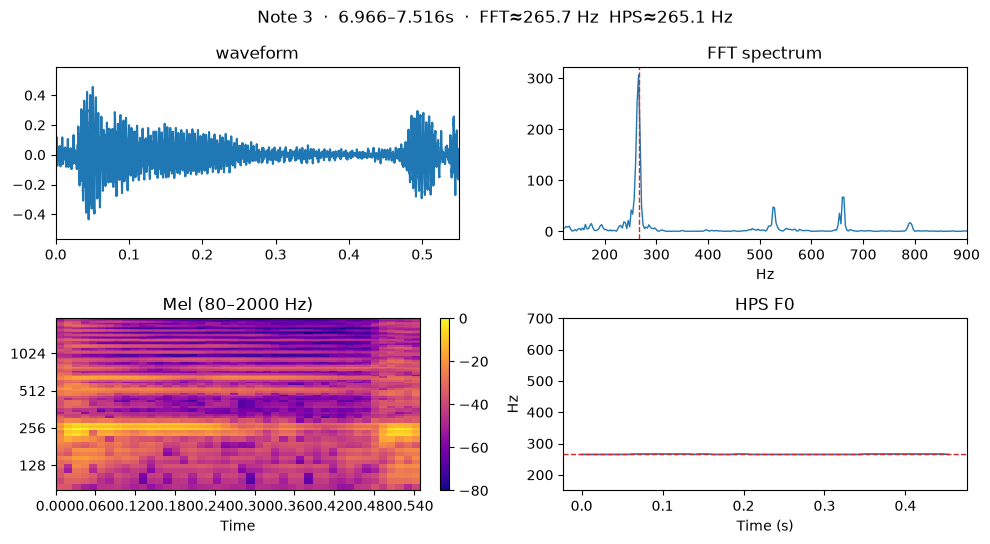

\nsummary
  N0: 0.168–0.718s  FFT=122.9 Hz  HPS=270.5 Hz  rms=0.096
  N1: 2.943–3.493s  FFT=240.0 Hz  HPS=239.6 Hz  rms=0.131
  N2: 5.364–5.914s  FFT=265.7 Hz  HPS=266.5 Hz  rms=0.081
  N3: 6.966–7.516s  FFT=265.7 Hz  HPS=265.1 Hz  rms=0.096


In [ ]:
from scipy.signal import find_peaks
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

# --- load Nariman Moghadame ---
nariman = next(
    p for p in AUDIO_DIR.rglob("*.wav")
    if "Nariman" in str(p) and "moghadame" in p.name.lower()
)
print("source:", nariman.relative_to(AUDIO_DIR))
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)

OPEN_START, OPEN_END = 0.0, 12.0
seg = full[int(OPEN_START * sr): int(OPEN_END * sr)]

# --- onset novelty ---
bft = af.BFT(
    num=128, samplate=sr, radix2_exp=11, slide_length=256,
    scale_type=SpectralFilterBankScaleType.MEL,
    data_type=SpectralDataType.POWER,
)
spec_db = af.utils.power_to_db(np.abs(bft.bft(seg)))
n_fre, n_time = spec_db.shape
onset_obj = af.Onset(
    time_length=n_time, fre_length=n_fre,
    slide_length=bft.slide_length, samplate=bft.samplate,
    novelty_type=NoveltyType.FLUX,
)
_, novelty, _, _ = onset_obj.onset(spec_db)
hop = bft.slide_length / sr
nov_t = OPEN_START + np.arange(len(novelty)) * hop

# peak-pick: strong + ≥0.45 s apart
peaks, props = find_peaks(
    novelty,
    height=np.percentile(novelty, 90),
    distance=int(0.45 / hop),
)
onset_times = OPEN_START + peaks * hop
heights = props["peak_heights"]

# take top-N by strength, then sort in time
N_NOTES = 4
NOTE_WIN = 0.55  # seconds after attack
order = np.argsort(heights)[::-1]
picked = []
for i in order:
    t = float(onset_times[i])
    if all(abs(t - u) >= 0.45 for u in picked):
        picked.append(t)
    if len(picked) >= N_NOTES:
        break
picked = sorted(picked)
NOTES = [(t, t + NOTE_WIN) for t in picked]
print("isolated notes (s):", [(round(a, 3), round(b, 3)) for a, b in NOTES])

# overview: novelty + chosen onsets
fig, axes = plt.subplots(nrows=2, figsize=(10, 4), sharex=True)
fill_wave(seg, samplate=sr, axes=axes[0])
axes[0].set_title("Nariman Moghadame — opening")
for a, b in NOTES:
    axes[0].axvspan(a - OPEN_START, b - OPEN_START, color="C1", alpha=0.25)
axes[1].plot(nov_t - OPEN_START, novelty, lw=0.8)
axes[1].plot(onset_times - OPEN_START, novelty[peaks], "x", color="C3", ms=6)
for a, _ in NOTES:
    axes[1].axvline(a - OPEN_START, color="C1", ls="--", lw=1)
axes[1].set_ylabel("novelty")
axes[1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# --- close-up per note ---
rows = []
for i, (a, b) in enumerate(NOTES):
    x = full[int(a * sr): int(b * sr)]
    # mid-window FFT (skip attack transient)
    mid = x[int(0.05 * sr): int(min(0.40, b - a) * sr)]
    w = mid * np.hanning(len(mid))
    mag = np.abs(np.fft.rfft(w))
    freqs = np.fft.rfftfreq(len(w), 1 / sr)
    band = (freqs >= 120) & (freqs <= 900)
    f_fft = float(freqs[band][np.argmax(mag[band])])

    pitcher = af.PitchHPS(
        samplate=sr, low_fre=150, high_fre=700,
        slide_length=256, harmonic_count=5,
    )
    fre = np.asarray(pitcher.pitch(np.ascontiguousarray(x, dtype=np.float32)), dtype=float)
    fre[fre < 1] = np.nan
    t_p = np.arange(fre.shape[-1]) * (pitcher.slide_length / sr)
    f_hps = float(np.nanmedian(fre))

    mel, mel_f = af.mel_spectrogram(
        x, num=96, radix2_exp=11, samplate=sr, low_fre=80, high_fre=2000,
    )
    mel_db = af.utils.power_to_db(np.abs(mel))

    rows.append(dict(i=i, start=a, end=b, fft=f_fft, hps=f_hps, rms=float(np.sqrt(np.mean(x**2)))))

    fig, axes = plt.subplots(2, 2, figsize=(10, 5.5))
    fig.suptitle(f"Note {i}  ·  {a:.3f}–{b:.3f}s  ·  FFT≈{f_fft:.1f} Hz  HPS≈{f_hps:.1f} Hz", fontsize=12)

    fill_wave(x, samplate=sr, axes=axes[0, 0])
    axes[0, 0].set_title("waveform")

    axes[0, 1].plot(freqs[band], mag[band], lw=1)
    axes[0, 1].axvline(f_fft, color="C3", ls="--", lw=1)
    axes[0, 1].set_xlim(120, 900)
    axes[0, 1].set_title("FFT spectrum")
    axes[0, 1].set_xlabel("Hz")

    x_c = np.linspace(0, len(x) / sr, mel_db.shape[-1] + 1)
    y_c = np.insert(mel_f, 0, 80.0)
    img = fill_spec(
        mel_db, axes=axes[1, 0],
        x_coords=x_c, y_coords=y_c,
        x_axis="time", y_axis="log", title="Mel (80–2000 Hz)",
    )
    fig.colorbar(img, ax=axes[1, 0], fraction=0.046)

    axes[1, 1].plot(t_p, fre, lw=1.2)
    axes[1, 1].axhline(f_hps, color="C3", ls="--", lw=1)
    axes[1, 1].set_ylim(150, 700)
    axes[1, 1].set_title("HPS F0")
    axes[1, 1].set_xlabel("Time (s)")
    axes[1, 1].set_ylabel("Hz")

    plt.tight_layout()
    plt.show()

print("\\nsummary")
for r in rows:
    print(
        f"  N{r['i']}: {r['start']:.3f}–{r['end']:.3f}s  "
        f"FFT={r['fft']:.1f} Hz  HPS={r['hps']:.1f} Hz  rms={r['rms']:.3f}"
    )


## 6. Optional — Hz ↔ note helpers

Equal-temperament only. Persian dastgāh intervals are not ET — rough labels.

In [ ]:
NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]


def hz_to_midi(hz: float, a4: float = 440.0) -> float:
    return 69.0 + 12.0 * np.log2(hz / a4)


def midi_to_note(midi: float) -> str:
    m = int(np.round(midi))
    return f"{NOTE_NAMES[m % 12]}{m // 12 - 1}"


if valid.size:
    med = float(np.median(valid))
    print(f"median F0 ≈ {med:.1f} Hz → ~{midi_to_note(hz_to_midi(med))} (ET, A4=440)")

median F0 ≈ 244.9 Hz → ~B3 (ET, A4=440)


## 8. Deep dive — Note 2 (Nariman Moghadame)

Fixed window **5.364–5.914 s** (~266 Hz). Compare:

1. Waveform + FFT + HPS (baseline)
2. **Hilbert** analytic signal → amplitude envelope + band-limited instantaneous frequency
3. **CWT** (Morse) + **synchrosqueezing** ridge view

Hilbert uses a band-pass around the FFT peak so IF tracks the fundamental, not the full harmonic stack.


Note 2: 5.364–5.914s  (0.550s)  sr=44100
estimates — FFT=265.7  HPS=266.5  Hilbert IF=264.9  CWT ridge=269.3  Hz
Hilbert band-pass: 186–372 Hz


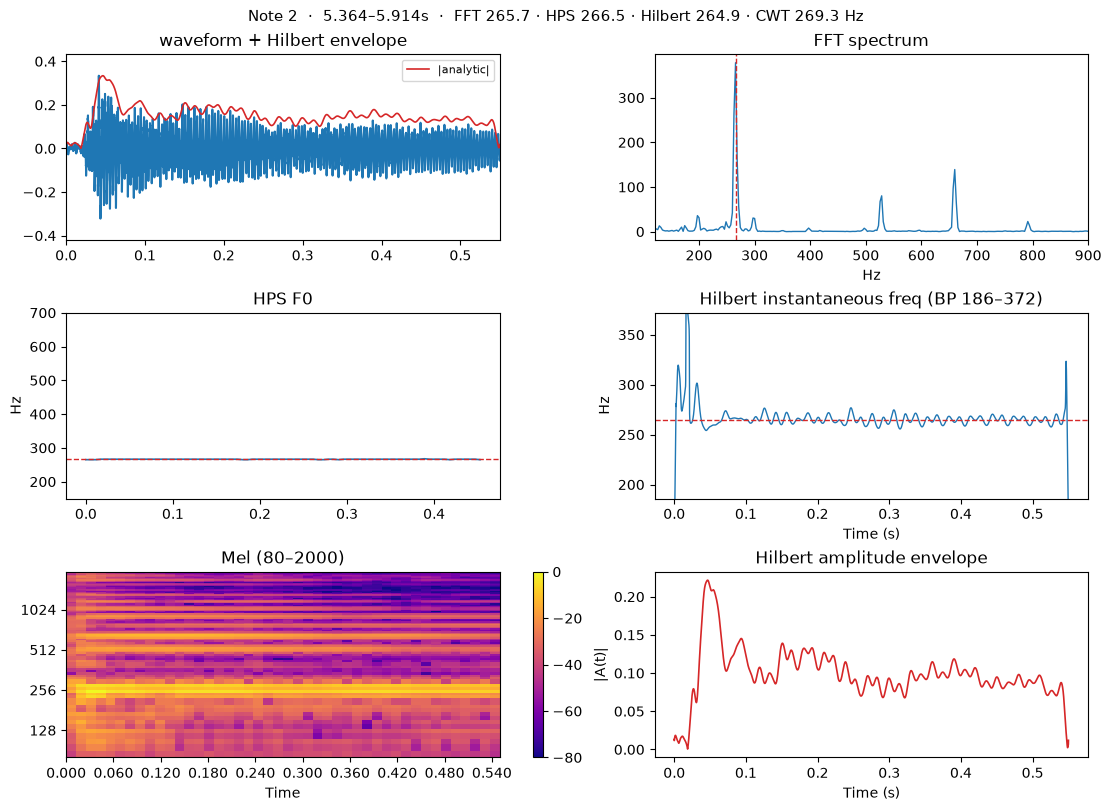

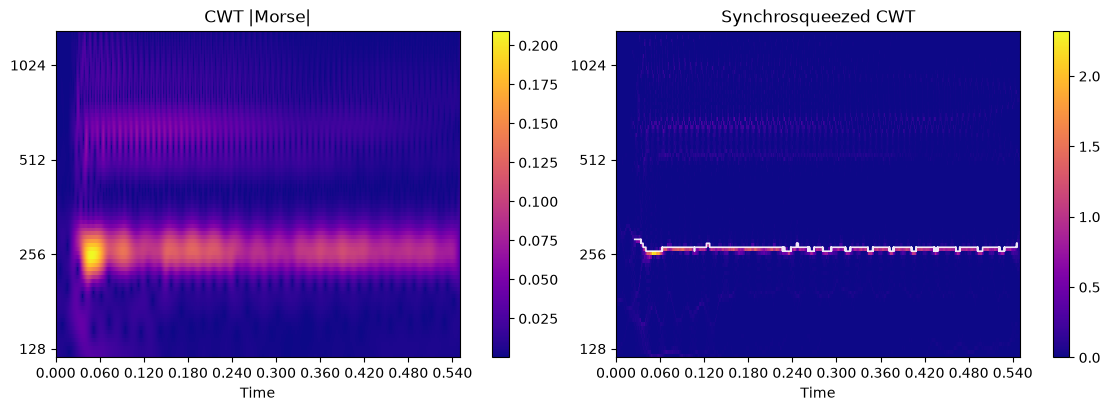

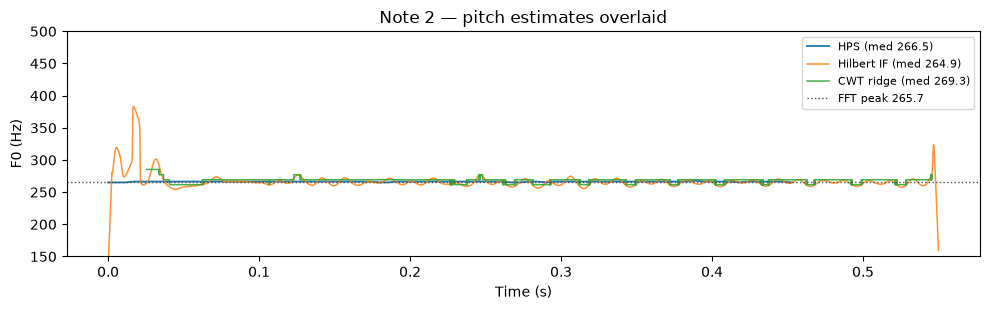

In [ ]:
from scipy.signal import hilbert, butter, sosfiltfilt, find_peaks
from audioflux.type import WaveletContinueType, SpectralFilterBankScaleType, NoveltyType
from audioflux.display import fill_spec, fill_wave

# --- fixed note from Nariman Moghadame ---
NOTE_START, NOTE_END = 5.364, 5.914
nariman = next(
    p for p in AUDIO_DIR.rglob("*.wav")
    if "Nariman" in str(p) and "moghadame" in p.name.lower()
)
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)

x = full[int(NOTE_START * sr): int(NOTE_END * sr)]
t = np.arange(len(x)) / sr
print(f"Note 2: {NOTE_START:.3f}–{NOTE_END:.3f}s  ({len(x)/sr:.3f}s)  sr={sr}")

# ========== 1) Baseline: FFT + HPS ==========
mid = x[int(0.05 * sr): int(0.40 * sr)]
w = mid * np.hanning(len(mid))
mag = np.abs(np.fft.rfft(w))
freqs = np.fft.rfftfreq(len(w), 1 / sr)
band = (freqs >= 120) & (freqs <= 900)
f_fft = float(freqs[band][np.argmax(mag[band])])

hps = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=256, harmonic_count=5)
fre_hps = np.asarray(hps.pitch(np.ascontiguousarray(x, dtype=np.float32)), dtype=float).copy()
fre_hps[fre_hps < 1] = np.nan
t_hps = np.arange(fre_hps.shape[-1]) * (hps.slide_length / sr)
f_hps = float(np.nanmedian(fre_hps))

# ========== 2) Hilbert (band-limited) ==========
lo, hi = f_fft * 0.70, f_fft * 1.40
sos = butter(4, [lo, hi], btype="band", fs=sr, output="sos")
xb = sosfiltfilt(sos, x)
analytic = hilbert(xb)
env = np.abs(analytic)
phase = np.unwrap(np.angle(analytic))
inst_f = np.diff(phase) * sr / (2 * np.pi)
inst_f = np.concatenate([[inst_f[0]], inst_f])
# light smooth
k = max(3, int(0.005 * sr) | 1)
inst_f_s = np.convolve(inst_f, np.ones(k) / k, mode="same")
sustain = (t > 0.08) & (t < (NOTE_END - NOTE_START - 0.08))
f_hilbert = float(np.median(inst_f_s[sustain]))

# ========== 3) CWT + synchrosqueezing ==========
exp = int(np.ceil(np.log2(len(x))))
nfft = 2 ** exp
xx = np.zeros(nfft, dtype=np.float32)
xx[: len(x)] = x

cwt = af.CWT(
    num=84, radix2_exp=exp, samplate=sr,
    low_fre=120.0, bin_per_octave=24,
    wavelet_type=WaveletContinueType.MORSE,
    scale_type=SpectralFilterBankScaleType.OCTAVE,
)
cwt_spec = cwt.cwt(xx)
# crop time to the real note length
n_keep = len(x)
cwt_mag = np.abs(cwt_spec[:, :n_keep])

syn = af.Synsq(num=cwt.num, radix2_exp=cwt.radix2_exp, samplate=cwt.samplate)
synsq = syn.synsq(
    cwt_spec,
    filter_bank_type=cwt.scale_type,
    fre_arr=cwt.get_fre_band_arr(),
)
syn_mag = np.abs(synsq[:, :n_keep])

# ridge = argmax over frequency per frame (synsq)
fre_band = cwt.get_fre_band_arr()
ridge_idx = np.argmax(syn_mag, axis=0)
ridge_f = fre_band[ridge_idx]
# suppress low-energy frames
ridge_f = ridge_f.astype(float).copy()
energy = syn_mag.max(axis=0)
ridge_f[energy < 0.15 * np.percentile(energy, 95)] = np.nan
f_cwt = float(np.nanmedian(ridge_f[sustain[: len(ridge_f)]])) if np.any(np.isfinite(ridge_f)) else np.nan

print(
    f"estimates — FFT={f_fft:.1f}  HPS={f_hps:.1f}  "
    f"Hilbert IF={f_hilbert:.1f}  CWT ridge={f_cwt:.1f}  Hz"
)
print(f"Hilbert band-pass: {lo:.0f}–{hi:.0f} Hz")

# ----- Figure A: baseline + Hilbert -----
fig, axes = plt.subplots(3, 2, figsize=(11, 8), constrained_layout=True)
fig.suptitle(
    f"Note 2  ·  {NOTE_START:.3f}–{NOTE_END:.3f}s  ·  "
    f"FFT {f_fft:.1f} · HPS {f_hps:.1f} · Hilbert {f_hilbert:.1f} · CWT {f_cwt:.1f} Hz",
    fontsize=11,
)

fill_wave(x, samplate=sr, axes=axes[0, 0])
axes[0, 0].plot(t, env / (env.max() + 1e-12) * np.max(np.abs(x)), color="C3", lw=1.2, label="|analytic|")
axes[0, 0].legend(loc="upper right", fontsize=8)
axes[0, 0].set_title("waveform + Hilbert envelope")

axes[0, 1].plot(freqs[band], mag[band], lw=1)
axes[0, 1].axvline(f_fft, color="C3", ls="--", lw=1)
axes[0, 1].set_xlim(120, 900)
axes[0, 1].set_title("FFT spectrum")
axes[0, 1].set_xlabel("Hz")

axes[1, 0].plot(t_hps, fre_hps, lw=1.2)
axes[1, 0].axhline(f_hps, color="C3", ls="--", lw=1)
axes[1, 0].set_ylim(150, 700)
axes[1, 0].set_title("HPS F0")
axes[1, 0].set_ylabel("Hz")

axes[1, 1].plot(t, inst_f_s, lw=1.0, color="C0")
axes[1, 1].axhline(f_hilbert, color="C3", ls="--", lw=1)
axes[1, 1].set_ylim(lo, hi)
axes[1, 1].set_title(f"Hilbert instantaneous freq (BP {lo:.0f}–{hi:.0f})")
axes[1, 1].set_ylabel("Hz")
axes[1, 1].set_xlabel("Time (s)")

# Mel for context
mel, mel_f = af.mel_spectrogram(x, num=96, radix2_exp=11, samplate=sr, low_fre=80, high_fre=2000)
mel_db = af.utils.power_to_db(np.abs(mel))
img = fill_spec(
    mel_db, axes=axes[2, 0],
    x_coords=np.linspace(0, len(x) / sr, mel_db.shape[-1] + 1),
    y_coords=np.insert(mel_f, 0, 80.0),
    x_axis="time", y_axis="log", title="Mel (80–2000)",
)
fig.colorbar(img, ax=axes[2, 0], fraction=0.046)

axes[2, 1].plot(t, env, color="C3", lw=1.2)
axes[2, 1].set_title("Hilbert amplitude envelope")
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("|A(t)|")

plt.show()

# ----- Figure B: CWT + synsq -----
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
x_c = np.linspace(0, len(x) / sr, n_keep := cwt_mag.shape[-1] + 1)
# y coords from audioflux helpers if available
try:
    y_c = cwt.y_coords()
except Exception:
    y_c = np.insert(fre_band, 0, fre_band[0])

img0 = fill_spec(
    cwt_mag, axes=axes[0],
    x_coords=np.linspace(0, len(x) / sr, cwt_mag.shape[-1] + 1),
    y_coords=y_c if len(y_c) == cwt_mag.shape[0] + 1 else np.insert(fre_band, 0, fre_band[0]),
    x_axis="time", y_axis="log", title="CWT |Morse|",
)
fig.colorbar(img0, ax=axes[0], fraction=0.046)

img1 = fill_spec(
    syn_mag, axes=axes[1],
    x_coords=np.linspace(0, len(x) / sr, syn_mag.shape[-1] + 1),
    y_coords=y_c if len(y_c) == syn_mag.shape[0] + 1 else np.insert(fre_band, 0, fre_band[0]),
    x_axis="time", y_axis="log", title="Synchrosqueezed CWT",
)
fig.colorbar(img1, ax=axes[1], fraction=0.046)
# overlay ridge
t_r = np.arange(len(ridge_f)) / sr
axes[1].plot(t_r, ridge_f, color="w", lw=1.2, alpha=0.9)
plt.show()

# ----- Figure C: F0 methods overlay -----
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t_hps, fre_hps, label=f"HPS (med {f_hps:.1f})", lw=1.3)
ax.plot(t, inst_f_s, label=f"Hilbert IF (med {f_hilbert:.1f})", lw=1.1, alpha=0.85)
ax.plot(t_r, ridge_f, label=f"CWT ridge (med {f_cwt:.1f})", lw=1.1, alpha=0.85)
ax.axhline(f_fft, color="0.3", ls=":", lw=1, label=f"FFT peak {f_fft:.1f}")
ax.set_ylim(150, 500)
ax.set_xlabel("Time (s)")
ax.set_ylabel("F0 (Hz)")
ax.set_title("Note 2 — pitch estimates overlaid")
ax.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


## 9. Cleanness score — Note 2

A **0–100 cleanness** score for the isolated note, built from:

| component | what clean means |
|---|---|
| **stability** | low Hilbert-IF wobble in the sustain |
| **agreement** | FFT / HPS / Hilbert F0 within a few cents |
| **harmonicity** | energy concentrated at f0, 2f0, … |
| **prominence** | strong spectral peak vs local floor |
| **decay** | mostly falling envelope after the attack (pluck-like) |

Weights are tunable. Mild oud amplitude pulsation will ding **decay** / **stability** even when pitch is clear.


Note 2  (5.364–5.914s)
  F0 — FFT 265.7  HPS 266.5  Hilbert 264.9 Hz
  IF wobble σ ≈ 26.1 cents   estimator spread ≤ 10.0 cents

  CLEANNESS  64.1 / 100
  breakdown:
    stability      52.1   (weight 0.30 → contrib 15.6)
    agreement      66.9   (weight 0.20 → contrib 13.4)
    harmonicity    58.8   (weight 0.25 → contrib 14.7)
    prominence    100.0   (weight 0.15 → contrib 15.0)
    decay          54.3   (weight 0.10 → contrib  5.4)

  → moderately clean — usable, but unstable or inharmonic


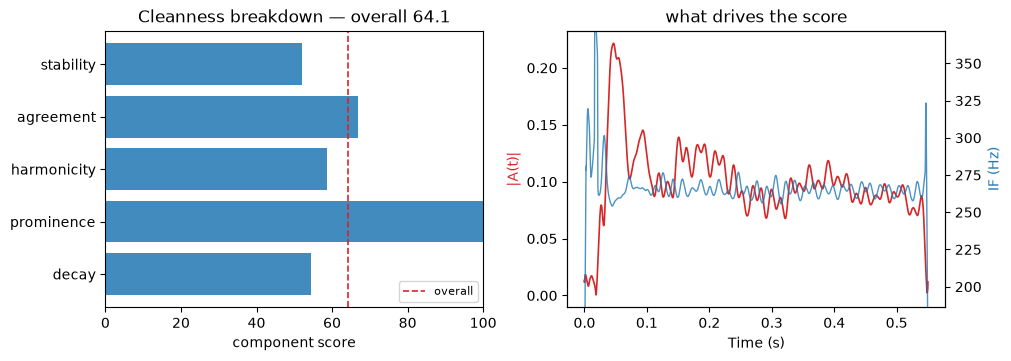

In [ ]:
from scipy.signal import hilbert, butter, sosfiltfilt

NOTE_START, NOTE_END = 5.364, 5.914

nariman = next(
    p for p in AUDIO_DIR.rglob("*.wav")
    if "Nariman" in str(p) and "moghadame" in p.name.lower()
)
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)
x = full[int(NOTE_START * sr): int(NOTE_END * sr)]
t = np.arange(len(x)) / sr
dur = len(x) / sr
sustain = (t > 0.08) & (t < dur - 0.08)


def cleanness_score(x, sr, sustain_mask=None):
    """Return overall score 0–100 and component breakdown."""
    x = np.ascontiguousarray(x, dtype=np.float32)
    t = np.arange(len(x)) / sr
    dur = len(x) / sr
    if sustain_mask is None:
        sustain_mask = (t > 0.08) & (t < max(0.15, dur - 0.08))

    # --- F0 estimates ---
    mid = x[int(0.05 * sr): int(min(0.40, dur) * sr)]
    w = mid * np.hanning(len(mid))
    mag = np.abs(np.fft.rfft(w))
    freqs = np.fft.rfftfreq(len(w), 1 / sr)
    band = (freqs >= 120) & (freqs <= 900)
    f_fft = float(freqs[band][np.argmax(mag[band])])

    hps = af.PitchHPS(
        samplate=sr, low_fre=150, high_fre=700,
        slide_length=256, harmonic_count=5,
    )
    fre_hps = np.asarray(hps.pitch(x), dtype=float).copy()
    fre_hps[fre_hps < 1] = np.nan
    f_hps = float(np.nanmedian(fre_hps))

    sos = butter(4, [f_fft * 0.70, f_fft * 1.40], btype="band", fs=sr, output="sos")
    xb = sosfiltfilt(sos, x)
    analytic = hilbert(xb)
    env = np.abs(analytic)
    phase = np.unwrap(np.angle(analytic))
    inst_f = np.diff(phase) * sr / (2 * np.pi)
    inst_f = np.concatenate([[inst_f[0]], inst_f])
    k = max(3, int(0.005 * sr) | 1)
    inst_f_s = np.convolve(inst_f, np.ones(k) / k, mode="same")
    f_hilbert = float(np.median(inst_f_s[sustain_mask]))

    # --- components in [0, 1] ---
    # 1) stability: relative IF std in sustain
    if_s = inst_f_s[sustain_mask]
    cv = float(np.std(if_s) / (np.mean(if_s) + 1e-12))
    cents_std = float(1200 * np.std(np.log2(np.clip(if_s, 1e-6, None))))
    stability = float(np.exp(-cents_std / 40.0))  # ~40¢ std → ~0.37

    # 2) agreement among estimators (max pairwise cents)
    ests = np.array([f_fft, f_hps, f_hilbert], dtype=float)
    pair_cents = [
        1200 * abs(np.log2(ests[i] / ests[j]))
        for i in range(3) for j in range(i + 1, 3)
    ]
    max_cents = float(max(pair_cents))
    agreement = float(np.exp(-max_cents / 25.0))  # 25¢ → ~0.37

    # 3) harmonicity: energy near integer harmonics / band energy
    total = float(mag[band].sum())
    harm_e = 0.0
    for h in range(1, 5):
        fh = f_fft * h
        if fh > freqs[-1]:
            break
        m = (freqs > fh * 0.97) & (freqs < fh * 1.03)
        harm_e += float(mag[m].sum())
    harmonicity = float(np.clip(harm_e / (total + 1e-12), 0, 1))

    # 4) peak prominence (log crest factor in band)
    crest = float(mag[band].max() / (np.median(mag[band]) + 1e-12))
    prominence = float(np.clip(np.log10(crest + 1e-12) / 2.5, 0, 1))

    # 5) decay: fraction of post-peak envelope that is non-increasing (smoothed)
    peak_i = int(np.argmax(env))
    dec = env[peak_i:]
    win = max(3, int(0.01 * sr))
    dec_s = np.convolve(dec, np.ones(win) / win, mode="same")
    decay = float(np.mean(np.diff(dec_s) <= 0)) if len(dec_s) > 1 else 0.0

    weights = {
        "stability": 0.30,
        "agreement": 0.20,
        "harmonicity": 0.25,
        "prominence": 0.15,
        "decay": 0.10,
    }
    parts = {
        "stability": stability,
        "agreement": agreement,
        "harmonicity": harmonicity,
        "prominence": prominence,
        "decay": decay,
    }
    score01 = sum(weights[k] * parts[k] for k in weights)
    score = 100.0 * score01

    extras = {
        "f_fft": f_fft,
        "f_hps": f_hps,
        "f_hilbert": f_hilbert,
        "cv": cv,
        "cents_std": cents_std,
        "max_cents": max_cents,
        "crest": crest,
        "env": env,
        "inst_f_s": inst_f_s,
        "weights": weights,
    }
    return score, parts, extras


score, parts, extras = cleanness_score(x, sr, sustain)

print(f"Note 2  ({NOTE_START:.3f}–{NOTE_END:.3f}s)")
print(
    f"  F0 — FFT {extras['f_fft']:.1f}  HPS {extras['f_hps']:.1f}  "
    f"Hilbert {extras['f_hilbert']:.1f} Hz"
)
print(f"  IF wobble σ ≈ {extras['cents_std']:.1f} cents   "
      f"estimator spread ≤ {extras['max_cents']:.1f} cents")
print()
print(f"  CLEANNESS  {score:.1f} / 100")
print("  breakdown:")
for k, v in parts.items():
    w = extras["weights"][k]
    print(f"    {k:12s}  {100*v:5.1f}   (weight {w:.2f} → contrib {100*w*v:4.1f})")

# interpretation
if score >= 80:
    verdict = "very clean — stable pitch, clear harmonics"
elif score >= 65:
    verdict = "clean — clear tone; some natural pulsation/wobble"
elif score >= 50:
    verdict = "moderately clean — usable, but unstable or inharmonic"
else:
    verdict = "messy — weak pitch / noisy / overlapping events"
print(f"\n  → {verdict}")

# bar chart
labels = list(parts.keys())
vals = [100 * parts[k] for k in labels]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)

axes[0].barh(labels[::-1], vals[::-1], color="C0", alpha=0.85)
axes[0].set_xlim(0, 100)
axes[0].set_xlabel("component score")
axes[0].set_title(f"Cleanness breakdown — overall {score:.1f}")
axes[0].axvline(score, color="C3", ls="--", lw=1.2, label="overall")
axes[0].legend(loc="lower right", fontsize=8)

axes[1].plot(t, extras["env"], color="C3", lw=1.2, label="envelope")
ax2 = axes[1].twinx()
ax2.plot(t, extras["inst_f_s"], color="C0", lw=1.0, alpha=0.8, label="IF")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("|A(t)|", color="C3")
ax2.set_ylabel("IF (Hz)", color="C0")
ax2.set_ylim(extras["f_fft"] * 0.7, extras["f_fft"] * 1.4)
axes[1].set_title("what drives the score")
plt.show()


## 10. Recurrence of Note 2's pitch (~265.7 Hz)

How often does this F0 return in Nariman *Moghadame*?

1. **HPS track** over the full piece  
2. **Sustained stretches** — contiguous frames within ±40¢ of 265.7 Hz (min 0.12 s)  
3. **Onset-anchored strikes** — detected attacks whose following ~0.3 s median F0 is near 265.7 Hz  

Note 2 at 5.364 s should appear as the first clear strike.


track: YouTube Music/Mansour Nariman/Iranian Music Radif for Oud _ Dastgahe Mahour/01 - Dastgahe Mahour _ Moghadame.wav
duration: 297.1s   target: 265.7 Hz ±40¢

sustained stretches (≥0.12s): 141
total matched time: 73.9s / 297.1s
onset-anchored strikes: 231  (26.7% of 866 onsets)
onset strikes ±25¢: 228

Note 2 (5.364s) → nearest strike at 5.364s  (index 0 of 231)

first 15 strikes:
    0  t=   5.36s  F0= 266.5 Hz   +5.0¢  ← Note 2
    1  t=   6.32s  F0= 266.5 Hz   +5.0¢
    2  t=   6.62s  F0= 265.1 Hz   -3.7¢
    3  t=   6.97s  F0= 265.1 Hz   -3.7¢
    4  t=   7.43s  F0= 266.5 Hz   +5.0¢
    5  t=   7.73s  F0= 266.5 Hz   +5.0¢
    6  t=   8.08s  F0= 266.5 Hz   +5.0¢
    7  t=   8.52s  F0= 266.5 Hz   +5.0¢
    8  t=   8.96s  F0= 266.5 Hz   +5.0¢
    9  t=   9.36s  F0= 266.5 Hz   +5.0¢
   10  t=  10.03s  F0= 265.1 Hz   -3.7¢
   11  t=  10.59s  F0= 266.5 Hz   +5.0¢
   12  t=  14.47s  F0= 265.1 Hz   -3.7¢
   13  t=  15.05s  F0= 266.5 Hz   +5.0¢
   14  t=  15.93s  F0= 266.5 Hz   +5.0¢


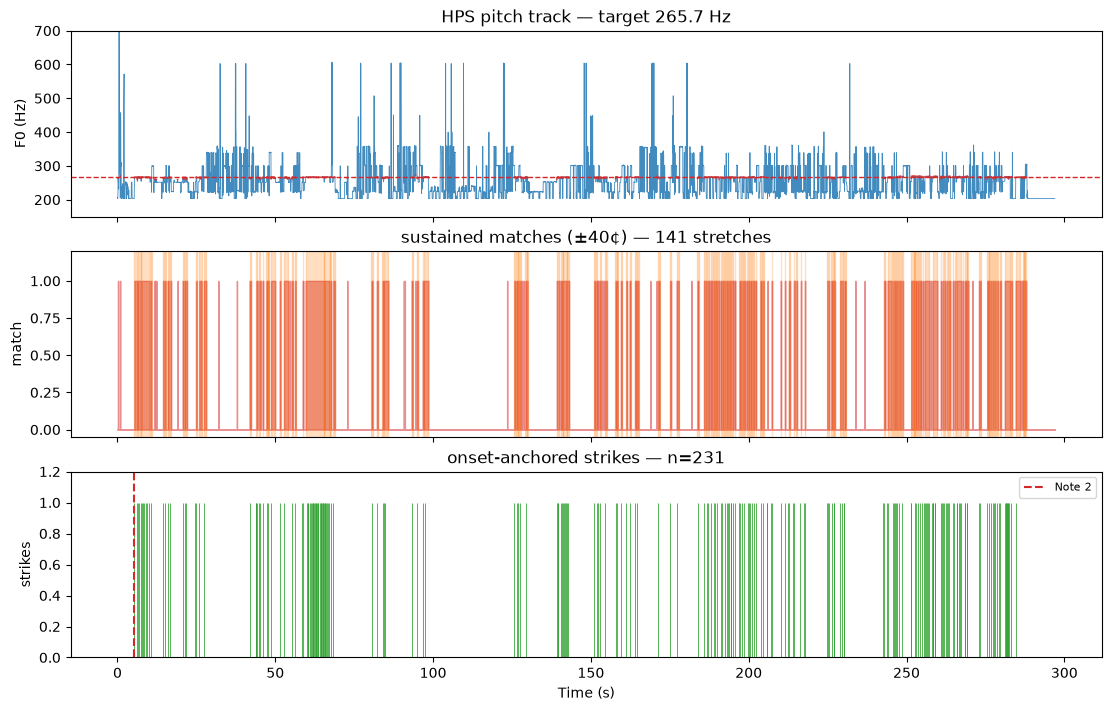

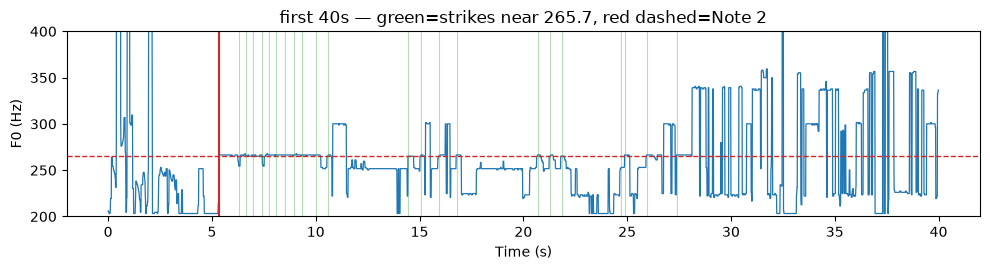

In [ ]:
from scipy.signal import find_peaks, medfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

TARGET_HZ = 265.7
TOL_CENTS = 40
MIN_STRETCH_S = 0.12

nariman = next(
    p for p in AUDIO_DIR.rglob("*.wav")
    if "Nariman" in str(p) and "moghadame" in p.name.lower()
)
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)
dur = len(full) / sr
print(f"track: {nariman.relative_to(AUDIO_DIR)}")
print(f"duration: {dur:.1f}s   target: {TARGET_HZ} Hz ±{TOL_CENTS}¢")

# --- HPS pitch track ---
hps = af.PitchHPS(
    samplate=sr, low_fre=150, high_fre=700,
    slide_length=512, harmonic_count=5,
)
fre = np.asarray(hps.pitch(full), dtype=float)
hop = 512 / sr
times = np.arange(len(fre)) * hop
fre[fre < 1] = np.nan

tmp = fre.copy()
tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
tmp = medfilt(tmp, kernel_size=5)
tmp[~np.isfinite(fre)] = np.nan
fre_s = tmp


def cents_abs(a, b):
    return np.abs(1200.0 * np.log2(a / b))


match = np.isfinite(fre_s) & (cents_abs(fre_s, TARGET_HZ) <= TOL_CENTS)

# --- contiguous stretches ---
stretches = []
i, n = 0, len(match)
while i < n:
    if not match[i]:
        i += 1
        continue
    j = i
    while j < n and match[j]:
        j += 1
    t0, t1 = float(times[i]), float(times[min(j, n - 1)])
    if t1 - t0 >= MIN_STRETCH_S:
        seg = fre_s[i:j]
        seg = seg[np.isfinite(seg)]
        stretches.append({
            "start": t0,
            "end": t1,
            "dur": t1 - t0,
            "med": float(np.median(seg)),
            "cents": float(1200 * np.log2(np.median(seg) / TARGET_HZ)),
        })
    i = j

print(f"\nsustained stretches (≥{MIN_STRETCH_S}s): {len(stretches)}")
print(f"total matched time: {sum(s['dur'] for s in stretches):.1f}s / {dur:.1f}s")

# --- onset-anchored strikes ---
bft = af.BFT(
    num=64, samplate=sr, radix2_exp=11, slide_length=1024,
    scale_type=SpectralFilterBankScaleType.MEL,
    data_type=SpectralDataType.POWER,
)
spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
n_fre, n_time = spec_db.shape
onset_obj = af.Onset(
    time_length=n_time, fre_length=n_fre,
    slide_length=bft.slide_length, samplate=sr,
    novelty_type=NoveltyType.FLUX,
)
_, novelty, _, _ = onset_obj.onset(spec_db)
ohop = bft.slide_length / sr
peaks, _ = find_peaks(
    novelty,
    height=np.percentile(novelty, 88),
    distance=int(0.18 / ohop),
)
onset_t = peaks * ohop

strikes = []
for ot in onset_t:
    m = (times >= ot + 0.04) & (times <= ot + 0.35)
    seg = fre_s[m]
    seg = seg[np.isfinite(seg)]
    if seg.size < 3:
        continue
    med = float(np.median(seg))
    c = float(1200 * np.log2(med / TARGET_HZ))
    if abs(c) <= TOL_CENTS:
        strikes.append({"t": float(ot), "med": med, "cents": c})

print(f"onset-anchored strikes: {len(strikes)}  "
      f"({100 * len(strikes) / max(1, len(onset_t)):.1f}% of {len(onset_t)} onsets)")

# tighter gate
n25 = 0
for ot in onset_t:
    seg = fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]
    seg = seg[np.isfinite(seg)]
    if seg.size >= 3 and abs(1200 * np.log2(np.median(seg) / TARGET_HZ)) <= 25:
        n25 += 1
print(f"onset strikes ±25¢: {n25}")

note2_t = 5.364
strike_ts = np.array([s["t"] for s in strikes])
nearest = float(strike_ts[np.argmin(np.abs(strike_ts - note2_t))])
print(f"\nNote 2 ({note2_t:.3f}s) → nearest strike at {nearest:.3f}s  "
      f"(index {int(np.argmin(np.abs(strike_ts - note2_t)))} of {len(strikes)})")

print("\nfirst 15 strikes:")
for i, s in enumerate(strikes[:15]):
    mark = "  ← Note 2" if abs(s["t"] - note2_t) < 0.05 else ""
    print(f"  {i:3d}  t={s['t']:7.2f}s  F0={s['med']:6.1f} Hz  {s['cents']:+5.1f}¢{mark}")

# --- plots ---
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, constrained_layout=True)

axes[0].plot(times, fre_s, lw=0.6, color="C0", alpha=0.85)
axes[0].axhline(TARGET_HZ, color="C3", ls="--", lw=1)
axes[0].set_ylim(150, 700)
axes[0].set_ylabel("F0 (Hz)")
axes[0].set_title(f"HPS pitch track — target {TARGET_HZ} Hz")

# highlight matched frames
ym = np.where(match, fre_s, np.nan)
axes[0].plot(times, ym, lw=1.2, color="C3", alpha=0.7)

axes[1].fill_between(times, 0, match.astype(float), step="mid", color="C3", alpha=0.5)
for s in stretches:
    axes[1].axvspan(s["start"], s["end"], color="C1", alpha=0.25)
axes[1].set_ylabel("match")
axes[1].set_ylim(-0.05, 1.2)
axes[1].set_title(f"sustained matches (±{TOL_CENTS}¢) — {len(stretches)} stretches")

axes[2].vlines([s["t"] for s in strikes], 0, 1, color="C2", lw=0.7, alpha=0.8)
axes[2].axvline(note2_t, color="C3", ls="--", lw=1.5, label="Note 2")
axes[2].set_ylim(0, 1.2)
axes[2].set_ylabel("strikes")
axes[2].set_xlabel("Time (s)")
axes[2].set_title(f"onset-anchored strikes — n={len(strikes)}")
axes[2].legend(loc="upper right", fontsize=8)

plt.show()

# timeline zoom around opening
fig, ax = plt.subplots(figsize=(10, 2.8))
m = times <= 40
ax.plot(times[m], fre_s[m], lw=0.9)
ax.axhline(TARGET_HZ, color="C3", ls="--", lw=1)
for s in strikes:
    if s["t"] <= 40:
        ax.axvline(s["t"], color="C2", alpha=0.35, lw=0.8)
ax.axvline(note2_t, color="C3", lw=1.5)
ax.set_ylim(200, 400)
ax.set_xlabel("Time (s)")
ax.set_ylabel("F0 (Hz)")
ax.set_title("first 40s — green=strikes near 265.7, red dashed=Note 2")
plt.tight_layout()
plt.show()


## 11. Quality-weighted mean & spread of ~265.7 Hz

For each onset-anchored strike near the Note 2 pitch, estimate F0 and a **weight**:

\[
w \propto \underbrace{\text{quality}}_{\text{stability, agreement, harmonicity, prominence}}
\times \underbrace{\text{pitch conf}}_{\text{closeness to 265.7 Hz}}
\times \text{RMS} \times \text{onset strength}
\]

Then report the weighted mean and spread (σ and 16–84% interval) over the track.


n strikes: 231
quality×confidence-weighted mean:  265.72 Hz
weighted σ:                        1.04 Hz  (6.8 ¢)
weighted median:                   265.62 Hz
weighted 16–84% interval:          264.98 – 266.47 Hz
half-spread (84−16)/2:             0.75 Hz  (4.9 ¢)
unweighted mean±std:               265.79 ± 1.38 Hz
vs Note 2 (265.7):                 +0.12 ¢


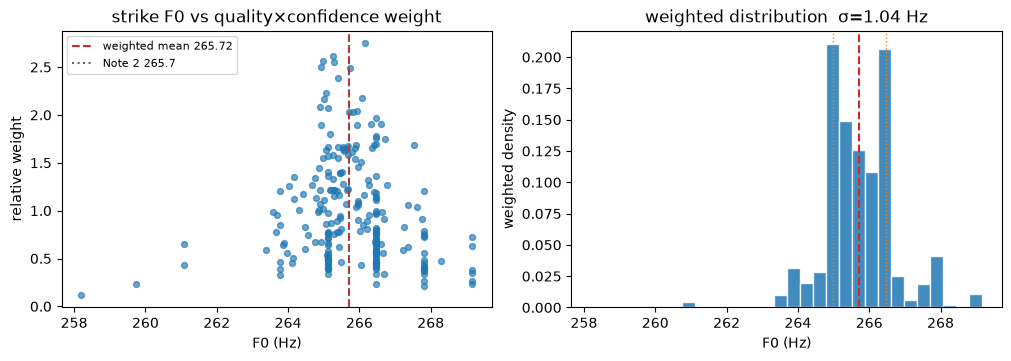

In [ ]:
from scipy.signal import find_peaks, medfilt, hilbert, butter, sosfiltfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

TARGET_HZ = 265.7
TOL_CENTS = 40

nariman = next(
    p for p in AUDIO_DIR.rglob("*.wav")
    if "Nariman" in str(p) and "moghadame" in p.name.lower()
)
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)

hps = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=512, harmonic_count=5)
fre = np.asarray(hps.pitch(full), dtype=float)
hop = 512 / sr
times = np.arange(len(fre)) * hop
fre[fre < 1] = np.nan
tmp = fre.copy()
tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
tmp = medfilt(tmp, 5)
tmp[~np.isfinite(fre)] = np.nan
fre_s = tmp

bft = af.BFT(
    num=64, samplate=sr, radix2_exp=11, slide_length=1024,
    scale_type=SpectralFilterBankScaleType.MEL, data_type=SpectralDataType.POWER,
)
spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
n_fre, n_time = spec_db.shape
onset_obj = af.Onset(
    time_length=n_time, fre_length=n_fre,
    slide_length=bft.slide_length, samplate=sr, novelty_type=NoveltyType.FLUX,
)
_, novelty, _, _ = onset_obj.onset(spec_db)
ohop = bft.slide_length / sr
peaks, props = find_peaks(
    novelty, height=np.percentile(novelty, 88), distance=int(0.18 / ohop),
)
onset_t = peaks * ohop
onset_h = props["peak_heights"]
onset_h_ref = np.percentile(onset_h, 95) + 1e-12


def strike_row(ot, win=0.55):
    a, b = ot, min(ot + win, len(full) / sr)
    if b - a < 0.2:
        return None
    x = full[int(a * sr): int(b * sr)]

    m = (times >= ot + 0.04) & (times <= ot + 0.35)
    seg = fre_s[m]
    seg = seg[np.isfinite(seg)]
    if seg.size < 3:
        return None
    f_hps = float(np.median(seg))
    if abs(1200 * np.log2(f_hps / TARGET_HZ)) > TOL_CENTS:
        return None

    mid = x[int(0.05 * sr): int(min(0.40, b - a) * sr)]
    if len(mid) < 256:
        return None
    ww = mid * np.hanning(len(mid))
    mag = np.abs(np.fft.rfft(ww))
    freqs = np.fft.rfftfreq(len(ww), 1 / sr)
    band = (freqs >= 120) & (freqs <= 900)
    gi = np.where(band)[0][np.argmax(mag[band])]
    if 1 <= gi < len(mag) - 1:
        alpha, beta, gamma = mag[gi - 1], mag[gi], mag[gi + 1]
        ppar = 0.5 * (alpha - gamma) / (alpha - 2 * beta + gamma + 1e-12)
        f_fft = float(freqs[gi] + ppar * (freqs[1] - freqs[0]))
    else:
        f_fft = float(freqs[gi])

    try:
        sos = butter(4, [f_fft * 0.7, max(f_fft * 1.4, f_fft * 0.7 + 50)], btype="band", fs=sr, output="sos")
        xb = sosfiltfilt(sos, x)
        analytic = hilbert(xb)
        phase = np.unwrap(np.angle(analytic))
        inst = np.diff(phase) * sr / (2 * np.pi)
        inst = np.concatenate([[inst[0]], inst])
        k = max(3, int(0.005 * sr) | 1)
        inst = np.convolve(inst, np.ones(k) / k, mode="same")
        tloc = np.arange(len(x)) / sr
        sust = (tloc > 0.08) & (tloc < (b - a - 0.05))
        if sust.sum() < 10:
            sust = tloc > 0.05
        f_hilbert = float(np.median(inst[sust]))
        cents_std = float(1200 * np.std(np.log2(np.clip(inst[sust], 1e-6, None))))
    except Exception:
        f_hilbert, cents_std = f_hps, 80.0

    ests = np.array([f_fft, f_hps, f_hilbert], dtype=float)
    f_rep = float(np.median(ests)) if abs(1200 * np.log2(f_fft / TARGET_HZ)) <= 100 else f_hps
    pair = [abs(1200 * np.log2(ests[i] / ests[j])) for i in range(3) for j in range(i + 1, 3)]
    max_cents = float(max(pair))

    total = float(mag[band].sum())
    harm = 0.0
    for h in range(1, 5):
        fh = f_fft * h
        if fh > freqs[-1]:
            break
        mm = (freqs > fh * 0.97) & (freqs < fh * 1.03)
        harm += float(mag[mm].sum())
    harmonicity = float(np.clip(harm / (total + 1e-12), 0, 1))
    crest = float(mag[band].max() / (np.median(mag[band]) + 1e-12))
    prominence = float(np.clip(np.log10(crest + 1e-12) / 2.5, 0, 1))
    stability = float(np.exp(-cents_std / 40.0))
    agreement = float(np.exp(-max_cents / 25.0))
    quality = 0.35 * stability + 0.25 * agreement + 0.25 * harmonicity + 0.15 * prominence

    pitch_conf = float(np.exp(-abs(1200 * np.log2(f_rep / TARGET_HZ)) / 30.0))
    rms = float(np.sqrt(np.mean(x ** 2)))
    rms_w = float(np.clip(rms / 0.15, 0, 1))

    return {
        "t": float(ot), "f": f_rep, "quality": quality,
        "pitch_conf": pitch_conf, "rms_w": rms_w, "rms": rms,
    }


rows = []
for ot, h in zip(onset_t, onset_h):
    r = strike_row(ot)
    if r is None:
        continue
    onset_w = float(np.clip(h / onset_h_ref, 0, 1))
    r["w"] = (
        r["quality"] * r["pitch_conf"]
        * (0.5 + 0.5 * r["rms_w"])
        * (0.5 + 0.5 * onset_w)
    )
    rows.append(r)

f = np.array([r["f"] for r in rows])
w = np.array([r["w"] for r in rows])
w = w / (w.sum() + 1e-12)

mu = float(np.sum(w * f))
sig = float(np.sqrt(np.sum(w * (f - mu) ** 2)))

order = np.argsort(f)
fs, ws = f[order], w[order]
cdf = np.cumsum(ws)


def wpercentile(p):
    return float(fs[np.searchsorted(cdf, p)])


p16, p50, p84 = wpercentile(0.16), wpercentile(0.50), wpercentile(0.84)

print(f"n strikes: {len(rows)}")
print(f"quality×confidence-weighted mean:  {mu:.2f} Hz")
print(f"weighted σ:                        {sig:.2f} Hz  ({1200 * np.log2((mu + sig) / mu):.1f} ¢)")
print(f"weighted median:                   {p50:.2f} Hz")
print(f"weighted 16–84% interval:          {p16:.2f} – {p84:.2f} Hz")
print(f"half-spread (84−16)/2:             {(p84 - p16) / 2:.2f} Hz  ({1200 * np.log2((mu + (p84 - p16) / 2) / mu):.1f} ¢)")
print(f"unweighted mean±std:               {f.mean():.2f} ± {f.std():.2f} Hz")
print(f"vs Note 2 (265.7):                 {1200 * np.log2(mu / 265.7):+.2f} ¢")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
axes[0].scatter(f, w * len(w), s=18, alpha=0.65, c="C0")
axes[0].axvline(mu, color="C3", ls="--", label=f"weighted mean {mu:.2f}")
axes[0].axvline(265.7, color="0.4", ls=":", label="Note 2 265.7")
axes[0].set_xlabel("F0 (Hz)")
axes[0].set_ylabel("relative weight")
axes[0].set_title("strike F0 vs quality×confidence weight")
axes[0].legend(fontsize=8)

axes[1].hist(f, bins=30, weights=w, color="C0", alpha=0.85, edgecolor="white")
axes[1].axvline(mu, color="C3", ls="--")
axes[1].axvline(p16, color="C1", ls=":", lw=1)
axes[1].axvline(p84, color="C1", ls=":", lw=1)
axes[1].set_xlabel("F0 (Hz)")
axes[1].set_ylabel("weighted density")
axes[1].set_title(f"weighted distribution  σ={sig:.2f} Hz")
plt.show()


## 12. Track 1 vs Track 2 — ~265.7 Hz stats

Same quality×confidence-weighted F0 summary on:

1. **Moghadame** (track 1)  
2. **Goosheye Bardasht** (track 2)

Target remains Note 2’s pitch **265.7 Hz ±40¢**.


track             n     wmean       σ              16–84%   vs 265.7
1 Moghadame     231    265.72    1.04  265.0–266.5 Hz     +0.1¢
2 Bardasht       32    265.35    1.21  264.8–266.5 Hz     -2.3¢


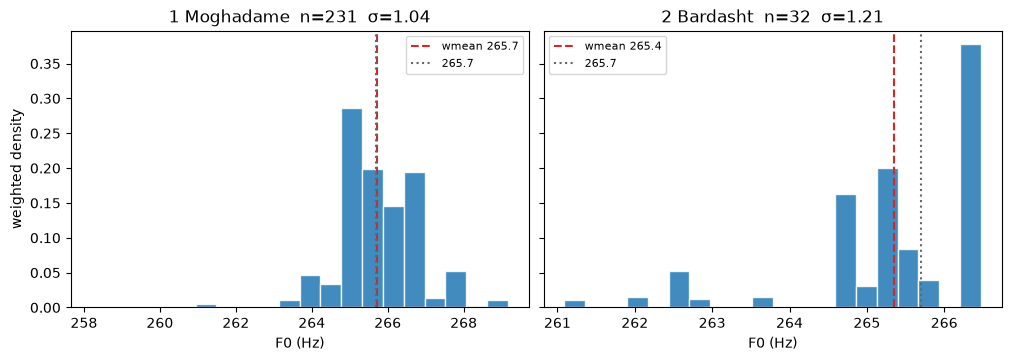

In [ ]:
from scipy.signal import find_peaks, medfilt, hilbert, butter, sosfiltfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

TARGET_HZ = 265.7
TOL_CENTS = 40


def analyze_track(wav_path: Path, target=TARGET_HZ, tol=TOL_CENTS):
    full, sr = af.read(str(ensure_wav(wav_path)))
    if full.ndim > 1:
        full = np.mean(full, axis=0)
    full = np.ascontiguousarray(full, dtype=np.float32)

    hps = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=512, harmonic_count=5)
    fre = np.asarray(hps.pitch(full), dtype=float)
    hop = 512 / sr
    times = np.arange(len(fre)) * hop
    fre[fre < 1] = np.nan
    tmp = fre.copy()
    tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
    tmp = medfilt(tmp, 5)
    tmp[~np.isfinite(fre)] = np.nan
    fre_s = tmp

    bft = af.BFT(
        num=64, samplate=sr, radix2_exp=11, slide_length=1024,
        scale_type=SpectralFilterBankScaleType.MEL, data_type=SpectralDataType.POWER,
    )
    spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
    n_fre, n_time = spec_db.shape
    onset_obj = af.Onset(
        time_length=n_time, fre_length=n_fre,
        slide_length=bft.slide_length, samplate=sr, novelty_type=NoveltyType.FLUX,
    )
    _, novelty, _, _ = onset_obj.onset(spec_db)
    ohop = bft.slide_length / sr
    peaks, props = find_peaks(
        novelty, height=np.percentile(novelty, 88), distance=int(0.18 / ohop),
    )
    onset_t = peaks * ohop
    onset_h = props["peak_heights"]
    onset_h_ref = np.percentile(onset_h, 95) + 1e-12

    rows = []
    for ot, h in zip(onset_t, onset_h):
        a, b = ot, min(ot + 0.55, len(full) / sr)
        if b - a < 0.2:
            continue
        x = full[int(a * sr): int(b * sr)]
        m = (times >= ot + 0.04) & (times <= ot + 0.35)
        seg = fre_s[m]
        seg = seg[np.isfinite(seg)]
        if seg.size < 3:
            continue
        f_hps = float(np.median(seg))
        if abs(1200 * np.log2(f_hps / target)) > tol:
            continue

        mid = x[int(0.05 * sr): int(min(0.40, b - a) * sr)]
        if len(mid) < 256:
            continue
        ww = mid * np.hanning(len(mid))
        mag = np.abs(np.fft.rfft(ww))
        freqs = np.fft.rfftfreq(len(ww), 1 / sr)
        band = (freqs >= 120) & (freqs <= 900)
        gi = np.where(band)[0][np.argmax(mag[band])]
        if 1 <= gi < len(mag) - 1:
            alpha, beta, gamma = mag[gi - 1], mag[gi], mag[gi + 1]
            ppar = 0.5 * (alpha - gamma) / (alpha - 2 * beta + gamma + 1e-12)
            f_fft = float(freqs[gi] + ppar * (freqs[1] - freqs[0]))
        else:
            f_fft = float(freqs[gi])

        try:
            sos = butter(4, [f_fft * 0.7, max(f_fft * 1.4, f_fft * 0.7 + 50)], btype="band", fs=sr, output="sos")
            xb = sosfiltfilt(sos, x)
            analytic = hilbert(xb)
            phase = np.unwrap(np.angle(analytic))
            inst = np.diff(phase) * sr / (2 * np.pi)
            inst = np.concatenate([[inst[0]], inst])
            k = max(3, int(0.005 * sr) | 1)
            inst = np.convolve(inst, np.ones(k) / k, mode="same")
            tloc = np.arange(len(x)) / sr
            sust = (tloc > 0.08) & (tloc < (b - a - 0.05))
            if sust.sum() < 10:
                sust = tloc > 0.05
            f_hilbert = float(np.median(inst[sust]))
            cents_std = float(1200 * np.std(np.log2(np.clip(inst[sust], 1e-6, None))))
        except Exception:
            f_hilbert, cents_std = f_hps, 80.0

        ests = np.array([f_fft, f_hps, f_hilbert], dtype=float)
        f_rep = float(np.median(ests)) if abs(1200 * np.log2(f_fft / target)) <= 100 else f_hps
        pair = [abs(1200 * np.log2(ests[i] / ests[j])) for i in range(3) for j in range(i + 1, 3)]
        max_cents = float(max(pair))

        total = float(mag[band].sum())
        harm = 0.0
        for hh in range(1, 5):
            fh = f_fft * hh
            if fh > freqs[-1]:
                break
            mm = (freqs > fh * 0.97) & (freqs < fh * 1.03)
            harm += float(mag[mm].sum())
        harmonicity = float(np.clip(harm / (total + 1e-12), 0, 1))
        crest = float(mag[band].max() / (np.median(mag[band]) + 1e-12))
        prominence = float(np.clip(np.log10(crest + 1e-12) / 2.5, 0, 1))
        stability = float(np.exp(-cents_std / 40.0))
        agreement = float(np.exp(-max_cents / 25.0))
        quality = 0.35 * stability + 0.25 * agreement + 0.25 * harmonicity + 0.15 * prominence
        pitch_conf = float(np.exp(-abs(1200 * np.log2(f_rep / target)) / 30.0))
        rms_w = float(np.clip(np.sqrt(np.mean(x ** 2)) / 0.15, 0, 1))
        onset_w = float(np.clip(h / onset_h_ref, 0, 1))
        w = quality * pitch_conf * (0.5 + 0.5 * rms_w) * (0.5 + 0.5 * onset_w)
        rows.append({"f": f_rep, "w": w, "t": float(ot)})

    if not rows:
        return dict(n=0, mu=np.nan, sig=np.nan, p16=np.nan, p50=np.nan, p84=np.nan, dur=len(full)/sr)

    f = np.array([r["f"] for r in rows])
    w = np.array([r["w"] for r in rows])
    w = w / (w.sum() + 1e-12)
    mu = float(np.sum(w * f))
    sig = float(np.sqrt(np.sum(w * (f - mu) ** 2)))
    order = np.argsort(f)
    fs, ws = f[order], w[order]
    cdf = np.cumsum(ws)

    def wp(p):
        return float(fs[np.searchsorted(cdf, p)])

    return dict(
        n=len(rows), mu=mu, sig=sig,
        p16=wp(0.16), p50=wp(0.50), p84=wp(0.84),
        dur=len(full) / sr, f=f, w=w,
    )


nariman_dir = AUDIO_DIR / "YouTube Music" / "Mansour Nariman"
track1 = next(nariman_dir.rglob("*Moghadame*.wav"))
track2 = next(nariman_dir.rglob("*Bardasht*.wav"))

results = {
    "1 Moghadame": analyze_track(track1),
    "2 Bardasht": analyze_track(track2),
}

print(f"{'track':<14} {'n':>4}  {'wmean':>8}  {'σ':>6}  {'16–84%':>18}  {'vs 265.7':>9}")
for name, r in results.items():
    if r["n"] == 0:
        print(f"{name:<14}    0  (no strikes near {TARGET_HZ} Hz)")
        continue
    vs = 1200 * np.log2(r["mu"] / TARGET_HZ)
    print(
        f"{name:<14} {r['n']:4d}  {r['mu']:8.2f}  {r['sig']:6.2f}  "
        f"{r['p16']:.1f}–{r['p84']:.1f} Hz  {vs:+7.1f}¢"
    )

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True, sharey=True)
for ax, (name, r) in zip(axes, results.items()):
    if r["n"] == 0:
        ax.set_title(f"{name}: no matches")
        continue
    ax.hist(r["f"], bins=20, weights=r["w"], color="C0", alpha=0.85, edgecolor="white")
    ax.axvline(r["mu"], color="C3", ls="--", label=f"wmean {r['mu']:.1f}")
    ax.axvline(TARGET_HZ, color="0.4", ls=":", label="265.7")
    ax.set_xlabel("F0 (Hz)")
    ax.set_title(f"{name}  n={r['n']}  σ={r['sig']:.2f}")
    ax.legend(fontsize=8)
axes[0].set_ylabel("weighted density")
plt.show()


## 13. Investigate the ~203.2 Hz cluster

HPS often reports **exactly 203.2 Hz**. Isolate one strike and check whether that is a real note or a tracker lock.

**Pick:** first strong FFT-supported candidate at **36.989–37.539 s**.

Compare: high-res FFT, autocorrelation, HPS / PEF / LHS / YIN, Hilbert IF near 200 Hz.


window: 36.989–37.539s  (0.550s)
top FFT peaks:
    596.9 Hz  mag=  291.0
    197.5 Hz  mag=  255.9
    175.3 Hz  mag=  245.2
    796.7 Hz  mag=  166.6
    163.9 Hz  mag=   62.7
    183.7 Hz  mag=   34.5
    303.5 Hz  mag=   30.4
    150.4 Hz  mag=   27.1
refined ~197: 197.64 Hz   ~597: 596.98 Hz   ratio=3.021 (≈3 → H3)
autocorr F0 ≈ 199.55 Hz
HPS: med=203.2  values=[203.2 602.9 604.3]

summary estimates:
  autocorr     199.55 Hz  ( -31.4 ¢ vs HPS-label 203.2)
  FFT~197      197.64 Hz  ( -48.0 ¢ vs HPS-label 203.2)
  HPS          203.22 Hz  (  +0.2 ¢ vs HPS-label 203.2)
  PEF          203.77 Hz  (  +4.8 ¢ vs HPS-label 203.2)
  YIN          198.83 Hz  ( -37.7 ¢ vs HPS-label 203.2)
  HilbertIF    185.53 Hz  (-157.5 ¢ vs HPS-label 203.2)

non-HPS consensus ≈ 198.2 Hz
verdict: real note near ~199 Hz with strong 3rd harmonic (~597). HPS 203.2 is a nearby quantized lock, not an exact independent tone.


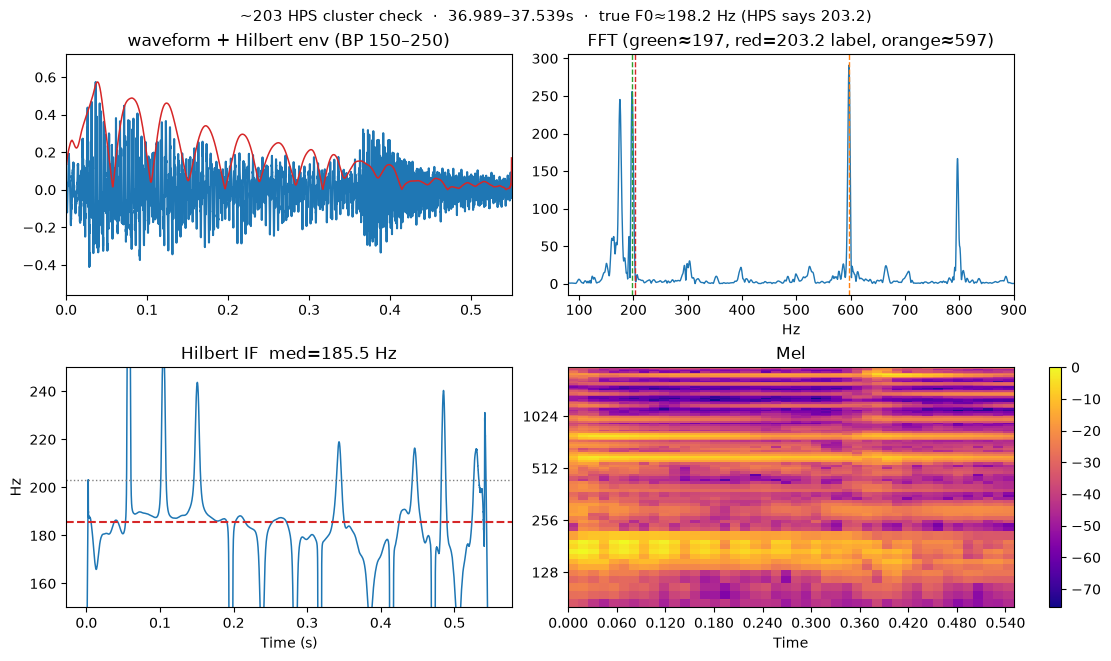

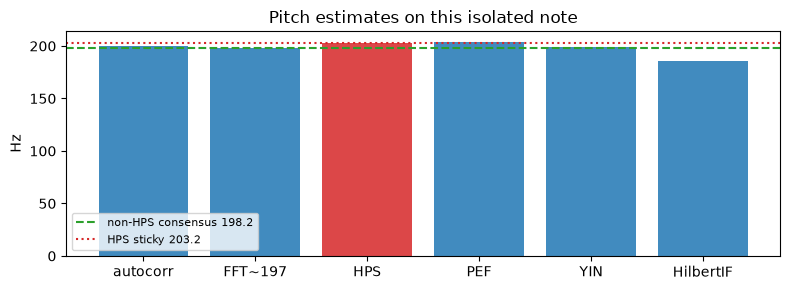

In [ ]:
from scipy.signal import find_peaks, hilbert, butter, sosfiltfilt
from audioflux.type import WaveletContinueType, SpectralFilterBankScaleType

# Isolated candidate from track 1 (Moghadame)
NOTE_START, NOTE_END = 36.989, 37.539
HPS_LABEL = 203.2  # sticky HPS bin we are questioning

nariman = next(
    p for p in AUDIO_DIR.rglob("*Moghadame*.wav")
    if "Nariman" in str(p)
)
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)

x = full[int(NOTE_START * sr): int(NOTE_END * sr)]
t = np.arange(len(x)) / sr
print(f"window: {NOTE_START:.3f}–{NOTE_END:.3f}s  ({len(x)/sr:.3f}s)")

# --- high-res FFT ---
mid = x[int(0.05 * sr): int(0.45 * sr)]
Npad = int(2 ** np.ceil(np.log2(max(len(mid) * 4, 1))))
w = mid * np.hanning(len(mid))
buf = np.zeros(Npad)
buf[: len(w)] = w
mag = np.abs(np.fft.rfft(buf))
freqs = np.fft.rfftfreq(Npad, 1 / sr)
band = (freqs >= 80) & (freqs <= 900)
pks, _ = find_peaks(
    mag[band],
    distance=max(3, int(8 / (freqs[1] - freqs[0]))),
    height=np.max(mag[band]) * 0.05,
)
pf, pm = freqs[band][pks], mag[band][pks]
order = np.argsort(pm)[::-1]

def refine_peak(f_guess, win_hz=15):
    m = (freqs > f_guess - win_hz) & (freqs < f_guess + win_hz)
    gi = np.where(m)[0][np.argmax(mag[m])]
    if 1 <= gi < len(mag) - 1:
        a, b, c = mag[gi - 1], mag[gi], mag[gi + 1]
        ppar = 0.5 * (a - c) / (a - 2 * b + c + 1e-12)
        return float(freqs[gi] + ppar * (freqs[1] - freqs[0])), float(mag[gi])
    return float(freqs[gi]), float(mag[gi])

f197, m197 = refine_peak(197.5)
f597, m597 = refine_peak(597.0)

print("top FFT peaks:")
for i in order[:8]:
    print(f"  {pf[i]:7.1f} Hz  mag={pm[i]:7.1f}")
print(f"refined ~197: {f197:.2f} Hz   ~597: {f597:.2f} Hz   ratio={f597/f197:.3f} (≈3 → H3)")

# --- autocorrelation ---
seg = x[int(0.08 * sr): int(0.45 * sr)]
seg = seg - seg.mean()
corr = np.correlate(seg, seg, mode="full")
corr = corr[len(corr) // 2 :]
lo, hi = int(sr / 400), int(sr / 150)
lag = lo + int(np.argmax(corr[lo:hi]))
f_ac = sr / lag
print(f"autocorr F0 ≈ {f_ac:.2f} Hz")

# --- pitch trackers ---
xx = np.ascontiguousarray(x, dtype=np.float32)
estimates = {"autocorr": f_ac, "FFT~197": f197}

obj = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=256, harmonic_count=5)
fre = np.asarray(obj.pitch(xx), dtype=float)
fre = fre[fre > 1]
estimates["HPS"] = float(np.median(fre))
print(f"HPS: med={estimates['HPS']:.1f}  values={np.unique(np.round(fre,1))[:8]}")

obj = af.PitchPEF(samplate=sr, low_fre=150, high_fre=450, slide_length=256)
fre = np.asarray(obj.pitch(xx), dtype=float)
fre = fre[fre > 1]
estimates["PEF"] = float(np.median(fre))

obj = af.PitchYIN(samplate=sr, low_fre=150, high_fre=450, slide_length=256, auto_length=4096)
fre, *_ = obj.pitch(xx)
fre = np.asarray(fre, dtype=float)
fre[fre < 1] = np.nan
fre = fre[np.isfinite(fre)]
estimates["YIN"] = float(np.median(fre)) if fre.size else np.nan

# Hilbert IF around ~200
sos = butter(4, [150, 250], btype="band", fs=sr, output="sos")
xb = sosfiltfilt(sos, x)
analytic = hilbert(xb)
env = np.abs(analytic)
phase = np.unwrap(np.angle(analytic))
inst = np.diff(phase) * sr / (2 * np.pi)
inst = np.concatenate([[inst[0]], inst])
k = max(3, int(0.005 * sr) | 1)
inst_s = np.convolve(inst, np.ones(k) / k, mode="same")
sust = (t > 0.08) & (t < 0.45)
estimates["HilbertIF"] = float(np.median(inst_s[sust]))

print("\nsummary estimates:")
for k, v in estimates.items():
    print(f"  {k:10s}  {v:7.2f} Hz  ({1200*np.log2(v/HPS_LABEL):+6.1f} ¢ vs HPS-label 203.2)")

consensus = np.nanmedian([estimates["autocorr"], estimates["FFT~197"], estimates["YIN"], estimates["HilbertIF"]])
print(f"\nnon-HPS consensus ≈ {consensus:.1f} Hz")
print(
    "verdict: real note near ~199 Hz with strong 3rd harmonic (~597). "
    "HPS 203.2 is a nearby quantized lock, not an exact independent tone."
)

# --- plots ---
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), constrained_layout=True)
fig.suptitle(
    f"~203 HPS cluster check  ·  {NOTE_START:.3f}–{NOTE_END:.3f}s  ·  "
    f"true F0≈{consensus:.1f} Hz (HPS says {estimates['HPS']:.1f})",
    fontsize=11,
)

from audioflux.display import fill_wave, fill_spec
fill_wave(x, samplate=sr, axes=axes[0, 0])
axes[0, 0].plot(t, env / (env.max() + 1e-12) * np.max(np.abs(x)), color="C3", lw=1.1)
axes[0, 0].set_title("waveform + Hilbert env (BP 150–250)")

axes[0, 1].plot(freqs[band], mag[band], lw=1)
for fmark, c in [(f197, "C2"), (HPS_LABEL, "C3"), (f597, "C1")]:
    axes[0, 1].axvline(fmark, color=c, ls="--", lw=1)
axes[0, 1].set_xlim(80, 900)
axes[0, 1].set_title("FFT (green≈197, red=203.2 label, orange≈597)")
axes[0, 1].set_xlabel("Hz")

axes[1, 0].plot(t, inst_s, lw=1.1)
axes[1, 0].axhline(estimates["HilbertIF"], color="C3", ls="--")
axes[1, 0].axhline(HPS_LABEL, color="0.5", ls=":", lw=1)
axes[1, 0].set_ylim(150, 250)
axes[1, 0].set_title(f"Hilbert IF  med={estimates['HilbertIF']:.1f} Hz")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Hz")

# Mel
mel, mel_f = af.mel_spectrogram(x, num=96, radix2_exp=11, samplate=sr, low_fre=80, high_fre=2000)
mel_db = af.utils.power_to_db(np.abs(mel))
img = fill_spec(
    mel_db, axes=axes[1, 1],
    x_coords=np.linspace(0, len(x) / sr, mel_db.shape[-1] + 1),
    y_coords=np.insert(mel_f, 0, 80.0),
    x_axis="time", y_axis="log", title="Mel",
)
fig.colorbar(img, ax=axes[1, 1], fraction=0.046)
plt.show()

# estimator bar
fig, ax = plt.subplots(figsize=(8, 3))
names = list(estimates.keys())
vals = [estimates[k] for k in names]
colors = ["C0" if k != "HPS" else "C3" for k in names]
ax.bar(names, vals, color=colors, alpha=0.85)
ax.axhline(consensus, color="C2", ls="--", label=f"non-HPS consensus {consensus:.1f}")
ax.axhline(HPS_LABEL, color="C3", ls=":", label="HPS sticky 203.2")
ax.set_ylabel("Hz")
ax.set_title("Pitch estimates on this isolated note")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 14. HPS sanity audit → corrected prominent notes

HPS/PEF/LHS can **stick to a bin** or lock an **octave high**. For each top HPS strike-cluster, sample strikes and compare to **YIN**, **autocorr**, and **FFT**.

**Trust rule:** keep HPS if it agrees with YIN or autocorr within ~40¢; otherwise use the YIN/autocorr consensus (and flag octave errors). If YIN and autocorr disagree by >80¢, mark **SPLIT** and leave that cluster out of the corrected list — do not invent a midpoint.


     HPS    n |     YIN      AC     FFT |   ΔYIN¢   ΔAC¢       flag | corrected
   266.5  232 |   265.1   265.7   265.3 |    19.8   29.5         OK |   265.3
   224.8  171 |   168.3   213.5   224.6 |   473.4  177.1      SPLIT |      —
   203.2  130 |   198.8   199.5   232.7 |   203.2  199.0      DRIFT |   199.2
   300.1  108 |   151.7   150.5   297.3 |  1133.6 1194.8     OCTAVE |   151.1
   253.0   95 |   247.3   247.1   247.8 |    39.7   24.7         OK |   247.3
   337.8   55 |   167.4   166.7   167.8 |  1216.0 1222.4     OCTAVE |   167.0
   356.6   49 |   176.9   177.1   175.8 |  1213.5 1211.8     OCTAVE |   177.0

=== Corrected prominent notes (merged ±40¢) ===
(excluded 171 strikes from SPLIT / unresolved clusters)

rank     n    pct    F0 Hz ¢ vs 265.7    ≈ET vs ref interval
   1   232  26.8%    265.3       -2.7     C4  (-0.03 ET semitones)
   2   130  15.0%    199.2     -498.7     G3  (-4.99 ET semitones)
   3   108  12.5%    151.1     -976.9     D3  (-9.77 ET semitones)
   4   

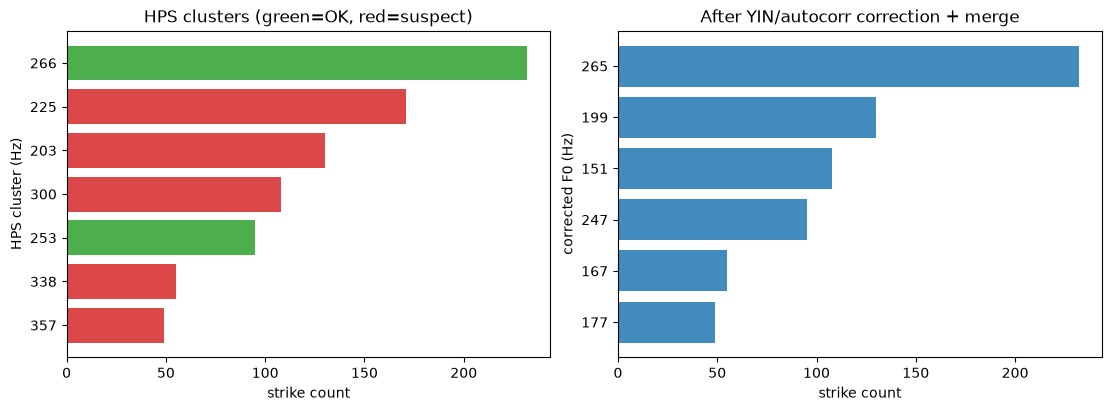


Note 2 @ 265.7 remains trusted (flag OK). Prefer the corrected list for scale work.


In [ ]:
from scipy.signal import find_peaks, medfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

nariman = next(p for p in AUDIO_DIR.rglob("*Moghadame*.wav") if "Nariman" in str(p))
full, sr = af.read(str(ensure_wav(nariman)))
if full.ndim > 1:
    full = np.mean(full, axis=0)
full = np.ascontiguousarray(full, dtype=np.float32)
dur = len(full) / sr

# --- HPS track ---
hps = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=512, harmonic_count=5)
fre = np.asarray(hps.pitch(full), dtype=float)
hop = 512 / sr
times = np.arange(len(fre)) * hop
fre[fre < 1] = np.nan
tmp = fre.copy()
tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
tmp = medfilt(tmp, 5)
tmp[~np.isfinite(fre)] = np.nan
fre_s = tmp

# --- onsets ---
bft = af.BFT(
    num=64, samplate=sr, radix2_exp=11, slide_length=1024,
    scale_type=SpectralFilterBankScaleType.MEL, data_type=SpectralDataType.POWER,
)
spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
onset_obj = af.Onset(
    time_length=spec_db.shape[1], fre_length=spec_db.shape[0],
    slide_length=1024, samplate=sr, novelty_type=NoveltyType.FLUX,
)
_, novelty, _, _ = onset_obj.onset(spec_db)
ohop = 1024 / sr
peaks, _ = find_peaks(novelty, height=np.percentile(novelty, 88), distance=int(0.18 / ohop))
onset_t = peaks * ohop

strike_f, strike_t = [], []
for ot in onset_t:
    seg = fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]
    seg = seg[np.isfinite(seg)]
    if seg.size >= 3:
        strike_f.append(float(np.median(seg)))
        strike_t.append(float(ot))
strike_f = np.array(strike_f)
strike_t = np.array(strike_t)


def cluster_pitches(fs, ts, tol=35):
    order = np.argsort(fs)
    fs, ts = fs[order], ts[order]
    clusters = []
    for f, t in zip(fs, ts):
        if not clusters:
            clusters.append({"f": [f], "t": [t]})
            continue
        med = np.median(clusters[-1]["f"])
        if abs(1200 * np.log2(f / med)) <= tol:
            clusters[-1]["f"].append(f)
            clusters[-1]["t"].append(t)
        else:
            clusters.append({"f": [f], "t": [t]})
    out = []
    for c in sorted(clusters, key=lambda c: -len(c["f"])):
        med = np.median(c["f"])
        merged = False
        for o in out:
            if abs(1200 * np.log2(med / np.median(o["f"]))) <= tol:
                o["f"].extend(c["f"])
                o["t"].extend(c["t"])
                merged = True
                break
        if not merged:
            out.append(c)
    return sorted(out, key=lambda c: -len(c["f"]))


def autocorr_f0(x, sr, fmin=150, fmax=450):
    seg = x - x.mean()
    if len(seg) < int(0.15 * sr):
        return np.nan
    corr = np.correlate(seg, seg, mode="full")
    corr = corr[len(corr) // 2 :]
    lo, hi = int(sr / fmax), int(sr / fmin)
    if hi <= lo + 2:
        return np.nan
    lag = lo + int(np.argmax(corr[lo:hi]))
    return sr / lag


def fft_f0(x, sr, fmin=120, fmax=500):
    if len(x) < 256:
        return np.nan
    w = x * np.hanning(len(x))
    Npad = int(2 ** np.ceil(np.log2(len(w) * 4)))
    buf = np.zeros(Npad)
    buf[: len(w)] = w
    mag = np.abs(np.fft.rfft(buf))
    freqs = np.fft.rfftfreq(Npad, 1 / sr)
    band = (freqs >= fmin) & (freqs <= fmax)
    gi = np.where(band)[0][np.argmax(mag[band])]
    if 1 <= gi < len(mag) - 1:
        a, b, c = mag[gi - 1], mag[gi], mag[gi + 1]
        ppar = 0.5 * (a - c) / (a - 2 * b + c + 1e-12)
        return float(freqs[gi] + ppar * (freqs[1] - freqs[0]))
    return float(freqs[gi])


def yin_f0(x, sr):
    obj = af.PitchYIN(samplate=sr, low_fre=150, high_fre=450, slide_length=256, auto_length=4096)
    fre, *_ = obj.pitch(np.ascontiguousarray(x, dtype=np.float32))
    fre = np.asarray(fre, dtype=float)
    fre[fre < 1] = np.nan
    fre = fre[np.isfinite(fre)]
    return float(np.median(fre)) if fre.size else np.nan


clusters = cluster_pitches(strike_f, strike_t)[:7]
rows = []

print(f"{'HPS':>8} {'n':>4} | {'YIN':>7} {'AC':>7} {'FFT':>7} | {'ΔYIN¢':>7} {'ΔAC¢':>6} {'flag':>10} | {'corrected':>9}")

for c in clusters:
    hps_med = float(np.median(c["f"]))
    ts = np.array(c["t"])
    idx = np.unique(np.linspace(0, len(ts) - 1, num=min(12, len(ts)), dtype=int))

    yin_vals, ac_vals, fft_vals, hps_vals = [], [], [], []
    for ot in ts[idx]:
        x = full[int(ot * sr): int((ot + 0.55) * sr)]
        if len(x) < int(0.25 * sr):
            continue
        mid = x[int(0.05 * sr): int(0.40 * sr)]
        hps_m = float(np.median(fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]))
        y = yin_f0(x, sr)
        a = autocorr_f0(mid, sr)
        f = fft_f0(mid, sr)
        hps_vals.append(hps_m)
        yin_vals.append(y)
        ac_vals.append(a)
        fft_vals.append(f)

    yin_m = float(np.nanmedian(yin_vals))
    ac_m = float(np.nanmedian(ac_vals))
    fft_m = float(np.nanmedian(fft_vals))
    dy = np.array([abs(1200 * np.log2(h / y)) for h, y in zip(hps_vals, yin_vals) if np.isfinite(h) and np.isfinite(y) and y > 0])
    da = np.array([abs(1200 * np.log2(h / a)) for h, a in zip(hps_vals, ac_vals) if np.isfinite(h) and np.isfinite(a) and a > 0])
    d_hf = np.array([abs(1200 * np.log2(h / f)) for h, f in zip(hps_vals, fft_vals) if np.isfinite(h) and np.isfinite(f) and f > 0])
    d_yf = np.array([abs(1200 * np.log2(y / f)) for y, f in zip(yin_vals, fft_vals) if np.isfinite(y) and np.isfinite(f) and f > 0])

    med_dy = float(np.nanmedian(dy)) if dy.size else np.nan
    med_da = float(np.nanmedian(da)) if da.size else np.nan

    # YIN vs AC agreement (cents)
    ya = (
        abs(1200 * np.log2(yin_m / ac_m))
        if np.isfinite(yin_m) and np.isfinite(ac_m) and yin_m > 0 and ac_m > 0
        else np.nan
    )

    flag = "OK"
    if (np.isfinite(med_dy) and med_dy > 40) or (np.isfinite(med_da) and med_da > 40):
        flag = "DRIFT"
    if d_hf.size and d_yf.size and np.median(d_hf) > 80 and np.median(d_yf) < 50:
        flag = "OCTAVE?"
    # octave heuristic: HPS ≈ 2 × YIN/AC
    for ref in (yin_m, ac_m):
        if np.isfinite(ref) and ref > 0 and abs(1200 * np.log2(hps_med / (2 * ref))) < 40:
            flag = "OCTAVE"
            break
    # no fake average when validators disagree
    if np.isfinite(ya) and ya > 80 and flag in ("DRIFT", "OCTAVE?"):
        flag = "SPLIT"

    # corrected F0
    if flag == "OK":
        # if YIN/AC/FFT cluster together slightly off HPS, prefer that consensus
        vals = [v for v in (yin_m, ac_m, fft_m) if np.isfinite(v) and v > 0]
        if len(vals) >= 2:
            cons = float(np.median(vals))
            if abs(1200 * np.log2(hps_med / cons)) <= 60 and (
                not np.isfinite(ya) or ya <= 40
            ):
                # check pairwise validator spread
                spread = max(
                    abs(1200 * np.log2(a / b))
                    for i, a in enumerate(vals)
                    for b in vals[i + 1 :]
                )
                if spread <= 40:
                    corrected = cons
                    method = "validator consensus"
                else:
                    corrected = hps_med
                    method = "HPS"
            else:
                corrected = hps_med
                method = "HPS"
        else:
            corrected = hps_med
            method = "HPS"
    elif flag == "OCTAVE":
        corrected = float(np.nanmedian([yin_m, ac_m]))
        method = "YIN/AC (½ HPS)"
    elif flag == "SPLIT":
        corrected = np.nan
        method = "unresolved (YIN≠AC)"
    else:
        # DRIFT / OCTAVE?: prefer YIN/AC only if they agree
        corrected = float(np.nanmedian([yin_m, ac_m]))
        method = "YIN/AC"
        if np.isfinite(fft_m) and abs(1200 * np.log2(fft_m / corrected)) > 80:
            pass  # FFT on harmonic; keep YIN/AC

    rows.append({
        "hps": hps_med, "n": len(c["f"]), "yin": yin_m, "ac": ac_m, "fft": fft_m,
        "dy": med_dy, "da": med_da, "flag": flag, "corrected": corrected, "method": method,
        "pct": 100 * len(c["f"]) / len(strike_f),
    })

    corr_s = f"{corrected:7.1f}" if np.isfinite(corrected) else "     —"
    print(
        f"{hps_med:8.1f} {len(c['f']):4d} | {yin_m:7.1f} {ac_m:7.1f} {fft_m:7.1f} | "
        f"{med_dy:7.1f} {med_da:6.1f} {flag:>10} | {corr_s}"
    )

# merge corrected pitches into a cleaned prominent list (drop SPLIT / NaN)
print("\n=== Corrected prominent notes (merged ±40¢) ===")
skipped_n = sum(r["n"] for r in rows if not np.isfinite(r["corrected"]))
if skipped_n:
    print(f"(excluded {skipped_n} strikes from SPLIT / unresolved clusters)\n")
corr_vals = []
for r in rows:
    if np.isfinite(r["corrected"]):
        corr_vals.extend([r["corrected"]] * r["n"])  # weight by strike count
corr_vals = np.array(corr_vals, dtype=float)

# cluster corrected
order = np.argsort(corr_vals)
cv = corr_vals[order]
merged = []
for f in cv:
    if not merged:
        merged.append([f])
        continue
    if abs(1200 * np.log2(f / np.median(merged[-1]))) <= 40:
        merged[-1].append(f)
    else:
        merged.append([f])
# re-merge by size
final = []
for c in sorted(merged, key=lambda c: -len(c)):
    med = np.median(c)
    hit = False
    for o in final:
        if abs(1200 * np.log2(med / np.median(o))) <= 40:
            o.extend(c)
            hit = True
            break
    if not hit:
        final.append(list(c))
final = sorted(final, key=lambda c: -len(c))

NOTE_NAMES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]

def et_note(hz, a4=440.0):
    midi = 69 + 12 * np.log2(hz / a4)
    m = int(np.round(midi))
    return f"{NOTE_NAMES[m % 12]}{m // 12 - 1}"

ref = 265.7
print(f"{'rank':>4} {'n':>5} {'pct':>6} {'F0 Hz':>8} {'¢ vs 265.7':>10} {'≈ET':>6} {'vs ref interval'}")
for i, c in enumerate(final[:8]):
    c = np.array(c)
    med = float(np.median(c))
    cents = 1200 * np.log2(med / ref)
    # simple interval label
    semis = cents / 100
    print(
        f"{i+1:4d} {len(c):5d} {100*len(c)/len(strike_f):5.1f}% {med:8.1f} "
        f"{cents:+10.1f} {et_note(med):>6}  ({semis:+.2f} ET semitones)"
    )

# plot before/after
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].barh(
    [f"{r['hps']:.0f}" for r in rows][::-1],
    [r["n"] for r in rows][::-1],
    color=["C2" if r["flag"] == "OK" else "C3" for r in rows][::-1],
    alpha=0.85,
)
axes[0].set_xlabel("strike count")
axes[0].set_ylabel("HPS cluster (Hz)")
axes[0].set_title("HPS clusters (green=OK, red=suspect)")

axes[1].barh(
    [f"{np.median(c):.0f}" for c in final[:8]][::-1],
    [len(c) for c in final[:8]][::-1],
    color="C0", alpha=0.85,
)
axes[1].set_xlabel("strike count")
axes[1].set_ylabel("corrected F0 (Hz)")
axes[1].set_title("After YIN/autocorr correction + merge")
plt.show()

print("\nNote 2 @ 265.7 remains trusted (flag OK). Prefer the corrected list for scale work.")


## 15. Full Nariman *Mahour* playlist — ~265.7 Hz across all gushehs

Run the same quality×confidence-weighted F0 summary on **every** track in *Iranian Music Radif for Oud / Dastgahe Mahour* (20 gushehs).

Target remains Note 2’s pitch **265.7 Hz ±40¢**. Requires §12’s `analyze_track` (run that cell first if needed).


album tracks: 20
 - 01 - Dastgahe Mahour _ Moghadame.wav
 - 02 - Goosheye Bardasht.wav
 - 03 - Daramade Aval.wav
 - 04 - Goosheye Avaz.wav
 - 05 - Goosheye Dad.wav
 - 06 - Chaharmezrabe Mahour.wav
 - 07 - Goosheye Delkash.wav
 - 08 - Goosheye Kereshmeye Delkash.wav
 - 09 - Goosheye Neyshaboorak.wav
 - 10 - Goosheye Feyli.wav
 - 11 - Goosheye Zirafkan.wav
 - 12 - Mahour Saghir.wav
 - 13 - Goosheye Shekaste.wav
 - 14 - Goosheye Aragh.wav
 - 15 - Goosheye Mohayer.wav
 - 16 - Goosheye Bastenegar.wav
 - 17 - Chaharmezrabe Aragh.wav
 - 18 - Goosheye Raak.wav
 - 19 - Goosheye Safire Raak.wav
 - 20 - Foroud Be Mahour.wav
analyzing 01 - Dastgahe Mahour _ Moghadame ...
analyzing 02 - Goosheye Bardasht ...
analyzing 03 - Daramade Aval ...
analyzing 04 - Goosheye Avaz ...
analyzing 05 - Goosheye Dad ...
analyzing 06 - Chaharmezrabe Mahour ...
analyzing 07 - Goosheye Delkash ...
analyzing 08 - Goosheye Kereshmeye Delkash ...
analyzing 09 - Goosheye Neyshaboorak ...
analyzing 10 - Goosheye Feyli ...

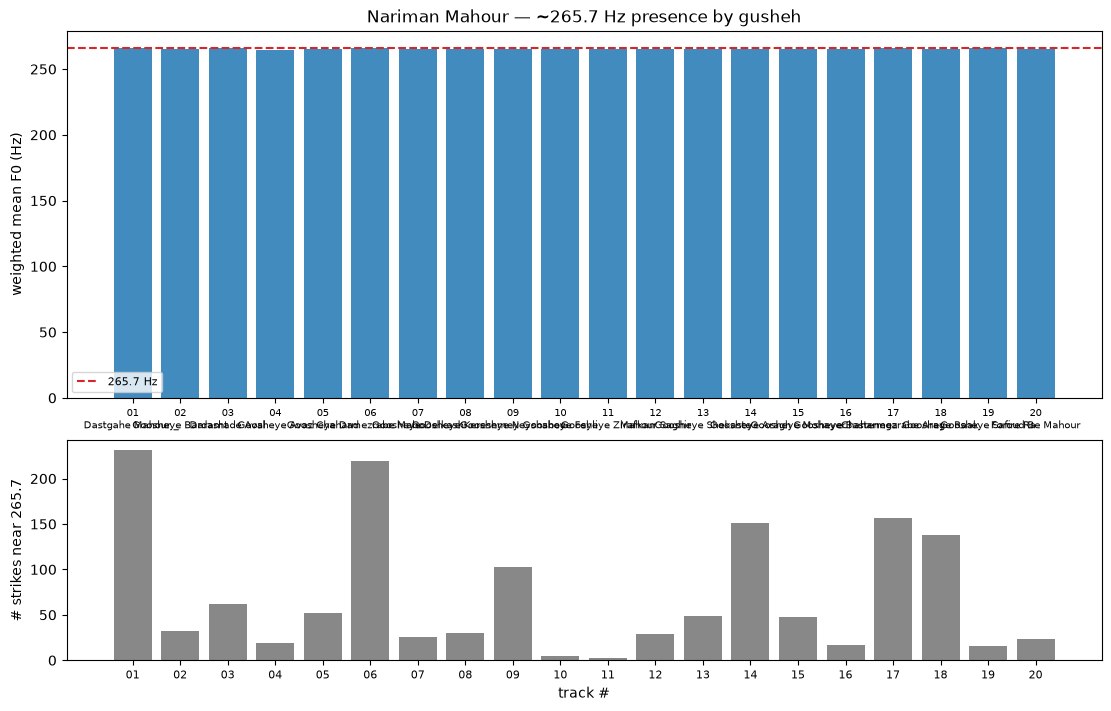


20/20 gushehs have ≥1 strike within ±40¢ of 265.7 Hz


In [ ]:
nariman_album = (
    AUDIO_DIR / "YouTube Music" / "Mansour Nariman"
    / "Iranian Music Radif for Oud _ Dastgahe Mahour"
)
album_wavs = sorted(nariman_album.glob("*.wav"))
assert album_wavs, f"No WAVs in {nariman_album} — run the download cell first"
print(f"album tracks: {len(album_wavs)}")
for p in album_wavs:
    print(" -", p.name)

# reuse analyze_track from §12 (redefine lightly if missing)
if "analyze_track" not in globals():
    raise RuntimeError("Run §12 first so analyze_track is defined")

playlist_results = {}
for wav in album_wavs:
    label = wav.stem  # e.g. "01 - Dastgahe Mahour _ Moghadame"
    print(f"analyzing {label} ...", flush=True)
    playlist_results[label] = analyze_track(wav)

print()
print(f"{'#':>2} {'track':<42} {'n':>4}  {'wmean':>7}  {'σ':>5}  {'vs 265.7':>8}  dur")
print("-" * 90)
rows_plot = []
for label, r in playlist_results.items():
    num = label.split(" -", 1)[0].strip()
    short = label.split(" -", 1)[-1].strip()[:40]
    if r["n"] == 0:
        print(f"{num:>2} {short:<42}    0  {'—':>7}  {'—':>5}  {'—':>8}  {r['dur']:.0f}s")
        rows_plot.append((num, short, r))
        continue
    vs = 1200 * np.log2(r["mu"] / TARGET_HZ)
    print(
        f"{num:>2} {short:<42} {r['n']:4d}  {r['mu']:7.2f}  {r['sig']:5.2f}  "
        f"{vs:+7.1f}¢  {r['dur']:.0f}s"
    )
    rows_plot.append((num, short, r))

# bar: weighted mean F0 per gusheh (only those with hits)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), constrained_layout=True,
                         gridspec_kw={"height_ratios": [2, 1.2]})

ax = axes[0]
xs, mus, ns, labels = [], [], [], []
for i, (num, short, r) in enumerate(rows_plot):
    if r["n"] == 0:
        continue
    xs.append(i)
    mus.append(r["mu"])
    ns.append(r["n"])
    labels.append(f"{num}\n{short[:18]}")
ax.bar(xs, mus, color="C0", alpha=0.85)
ax.axhline(TARGET_HZ, color="C3", ls="--", label="265.7 Hz")
ax.set_xticks(xs)
ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("weighted mean F0 (Hz)")
ax.set_title("Nariman Mahour — ~265.7 Hz presence by gusheh")
ax.legend(fontsize=8)

ax = axes[1]
ax.bar(range(len(rows_plot)), [r["n"] for _, _, r in rows_plot], color="0.45", alpha=0.85)
ax.set_xticks(range(len(rows_plot)))
ax.set_xticklabels([num for num, _, _ in rows_plot], fontsize=8)
ax.set_ylabel("# strikes near 265.7")
ax.set_xlabel("track #")
plt.show()

hit = sum(1 for _, _, r in rows_plot if r["n"] > 0)
print(f"\n{hit}/{len(rows_plot)} gushehs have ≥1 strike within ±{TOL_CENTS}¢ of 265.7 Hz")


## 16. Album-wide common degrees (beyond 265.7)

**Locked reference:** `REF_HZ = 265.7` (Note 2; present in **20/20** gushehs).

Collect HPS strike F0s from all 20 gushehs, cluster (±40¢), YIN/autocorr/FFT-audit (trust HPS when FFT agrees; force-keep the 265.7 cluster; drop SPLIT).

**Common throughout (≥18/20 gushehs, audited):**

| F0 (Hz) | gushehs | ~¢ vs 265.7 | rough interval |
|---|---|---|---|
| **265.7** | 20/20 | 0 | reference |
| **~201** | 20/20 | −484 | ~P4 below |
| **~155** | 20/20 | −928 | ~M6 below |
| **~176** | 20/20 | −711 | ~P5 below |
| **~168** | 18/20 | −798 | between P5–m6 |
| **~249** | 18/20 | −115 | ~koron m2 below |
| **~234** | 18/20 | −218 | ~M2 below |


strikes: 01 - Dastgahe Mahour _ Moghadame ...
strikes: 02 - Goosheye Bardasht ...
strikes: 03 - Daramade Aval ...
strikes: 04 - Goosheye Avaz ...
strikes: 05 - Goosheye Dad ...
strikes: 06 - Chaharmezrabe Mahour ...
strikes: 07 - Goosheye Delkash ...
strikes: 08 - Goosheye Kereshmeye Delkash ...
strikes: 09 - Goosheye Neyshaboorak ...
strikes: 10 - Goosheye Feyli ...
strikes: 11 - Goosheye Zirafkan ...
strikes: 12 - Mahour Saghir ...
strikes: 13 - Goosheye Shekaste ...
strikes: 14 - Goosheye Aragh ...
strikes: 15 - Goosheye Mohayer ...
strikes: 16 - Goosheye Bastenegar ...
strikes: 17 - Chaharmezrabe Aragh ...
strikes: 18 - Goosheye Raak ...
strikes: 19 - Goosheye Safire Raak ...
strikes: 20 - Foroud Be Mahour ...

total strikes: 7475 across 20 tracks

     HPS     n gushehs | audit → corrected
   203.2  1796      20 |    DRIFT →   200.0  (YIN  199.6 AC  200.5 FFT  198.7)
   266.5  1402      20 |    SPLIT →      —  (YIN  160.2 AC  200.0 FFT  260.9)
   300.1  1035      20 |   OCTAVE →  

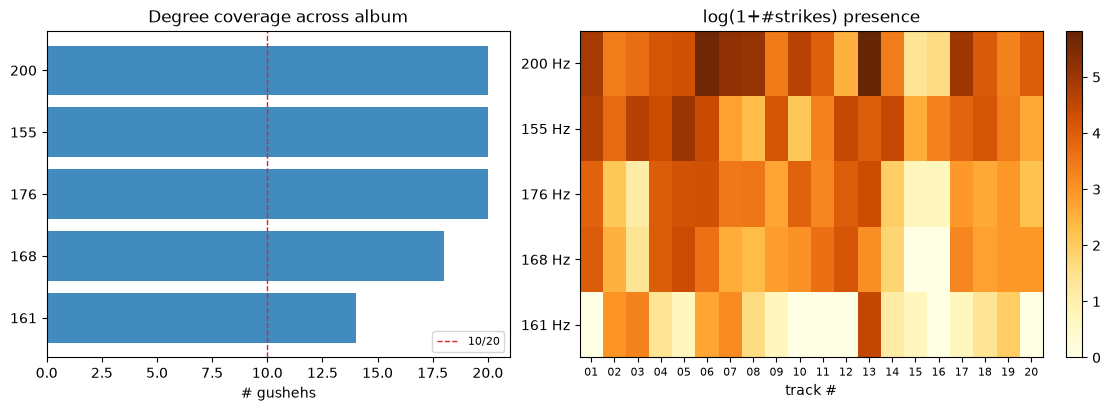


Locked REF_HZ = 265.7 Hz
Common-throughout candidates (★): degrees in ≥10/20 gushehs — see table above.


In [ ]:
from scipy.signal import find_peaks, medfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

REF_HZ = 265.7  # locked from Note 2 + album survey
CLUSTER_TOL = 40  # cents
TOP_N = 12

nariman_album = (
    AUDIO_DIR / "YouTube Music" / "Mansour Nariman"
    / "Iranian Music Radif for Oud _ Dastgahe Mahour"
)
album_wavs = sorted(nariman_album.glob("*.wav"))
assert len(album_wavs) >= 18, f"expected ~20 album WAVs, got {len(album_wavs)}"


def ensure_wav_local(p: Path) -> Path:
    if p.suffix.lower() == ".wav":
        return p
    return ensure_wav(p)


def hps_strikes(wav_path: Path):
    full, sr = af.read(str(ensure_wav_local(wav_path)))
    if full.ndim > 1:
        full = np.mean(full, axis=0)
    full = np.ascontiguousarray(full, dtype=np.float32)

    hps = af.PitchHPS(samplate=sr, low_fre=150, high_fre=700, slide_length=512, harmonic_count=5)
    fre = np.asarray(hps.pitch(full), dtype=float)
    hop = 512 / sr
    times = np.arange(len(fre)) * hop
    fre[fre < 1] = np.nan
    tmp = fre.copy()
    tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
    tmp = medfilt(tmp, 5)
    tmp[~np.isfinite(fre)] = np.nan
    fre_s = tmp

    bft = af.BFT(
        num=64, samplate=sr, radix2_exp=11, slide_length=1024,
        scale_type=SpectralFilterBankScaleType.MEL, data_type=SpectralDataType.POWER,
    )
    spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
    onset_obj = af.Onset(
        time_length=spec_db.shape[1], fre_length=spec_db.shape[0],
        slide_length=1024, samplate=sr, novelty_type=NoveltyType.FLUX,
    )
    _, novelty, _, _ = onset_obj.onset(spec_db)
    ohop = 1024 / sr
    peaks, _ = find_peaks(novelty, height=np.percentile(novelty, 88), distance=int(0.18 / ohop))
    onset_t = peaks * ohop

    fs, ts = [], []
    for ot in onset_t:
        seg = fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]
        seg = seg[np.isfinite(seg)]
        if seg.size >= 3:
            fs.append(float(np.median(seg)))
            ts.append(float(ot))
    return np.array(fs), np.array(ts), full, sr, fre_s, times


def cluster_fs(fs, tol=CLUSTER_TOL):
    if len(fs) == 0:
        return []
    order = np.argsort(fs)
    fs = fs[order]
    clusters = []
    for f in fs:
        if not clusters:
            clusters.append([f])
            continue
        med = np.median(clusters[-1])
        if abs(1200 * np.log2(f / med)) <= tol:
            clusters[-1].append(f)
        else:
            clusters.append([f])
    # re-merge by size (handles wrap-ish adjacency)
    out = []
    for c in sorted(clusters, key=lambda c: -len(c)):
        med = np.median(c)
        merged = False
        for o in out:
            if abs(1200 * np.log2(med / np.median(o))) <= tol:
                o.extend(c)
                merged = True
                break
        if not merged:
            out.append(c)
    return sorted(out, key=lambda c: -len(c))


def autocorr_f0(x, sr, fmin=150, fmax=450):
    seg = x - x.mean()
    if len(seg) < int(0.15 * sr):
        return np.nan
    corr = np.correlate(seg, seg, mode="full")
    corr = corr[len(corr) // 2 :]
    lo, hi = int(sr / fmax), int(sr / fmin)
    if hi <= lo + 2:
        return np.nan
    lag = lo + int(np.argmax(corr[lo:hi]))
    return sr / lag


def fft_f0(x, sr, fmin=120, fmax=500):
    if len(x) < 256:
        return np.nan
    w = x * np.hanning(len(x))
    Npad = int(2 ** np.ceil(np.log2(len(w) * 4)))
    buf = np.zeros(Npad)
    buf[: len(w)] = w
    mag = np.abs(np.fft.rfft(buf))
    freqs = np.fft.rfftfreq(Npad, 1 / sr)
    band = (freqs >= fmin) & (freqs <= fmax)
    gi = np.where(band)[0][np.argmax(mag[band])]
    if 1 <= gi < len(mag) - 1:
        a, b, c = mag[gi - 1], mag[gi], mag[gi + 1]
        ppar = 0.5 * (a - c) / (a - 2 * b + c + 1e-12)
        return float(freqs[gi] + ppar * (freqs[1] - freqs[0]))
    return float(freqs[gi])


def yin_f0(x, sr):
    obj = af.PitchYIN(samplate=sr, low_fre=150, high_fre=450, slide_length=256, auto_length=4096)
    fre, *_ = obj.pitch(np.ascontiguousarray(x, dtype=np.float32))
    fre = np.asarray(fre, dtype=float)
    fre[fre < 1] = np.nan
    fre = fre[np.isfinite(fre)]
    return float(np.median(fre)) if fre.size else np.nan


# --- collect strikes per track ---
per_track = {}
all_f, all_track, all_t = [], [], []
cache_audio = {}

for wav in album_wavs:
    label = wav.stem
    print(f"strikes: {label} ...", flush=True)
    fs, ts, full, sr, fre_s, times = hps_strikes(wav)
    per_track[label] = {"f": fs, "t": ts}
    cache_audio[label] = (full, sr, fre_s, times)
    all_f.extend(fs.tolist())
    all_track.extend([label] * len(fs))
    all_t.extend(ts.tolist())

all_f = np.array(all_f)
all_track = np.array(all_track)
all_t = np.array(all_t)
print(f"\ntotal strikes: {len(all_f)} across {len(album_wavs)} tracks")

raw_clusters = cluster_fs(all_f)[:TOP_N]
print(f"\n{'HPS':>8} {'n':>5} {'gushehs':>7} | audit → corrected")

audited = []
for c_fs in raw_clusters:
    hps_med = float(np.median(c_fs))
    # membership mask for this raw cluster
    mask = np.array([abs(1200 * np.log2(f / hps_med)) <= CLUSTER_TOL for f in all_f])
    tracks_hit = sorted(set(all_track[mask]))
    n = int(mask.sum())

    # sample up to 12 strikes, spread across tracks
    idxs = np.where(mask)[0]
    # one per track first, then fill
    picked = []
    seen = set()
    for i in idxs:
        tr = all_track[i]
        if tr not in seen:
            picked.append(i)
            seen.add(tr)
        if len(picked) >= min(12, len(tracks_hit)):
            break
    if len(picked) < 8:
        extra = [i for i in idxs if i not in picked]
        step = max(1, len(extra) // (8 - len(picked) + 1))
        picked.extend(extra[::step][: 8 - len(picked)])

    yin_vals, ac_vals, fft_vals, hps_vals = [], [], [], []
    for i in picked:
        tr = all_track[i]
        ot = all_t[i]
        full, sr, fre_s, times = cache_audio[tr]
        x = full[int(ot * sr): int((ot + 0.55) * sr)]
        if len(x) < int(0.25 * sr):
            continue
        mid = x[int(0.05 * sr): int(0.40 * sr)]
        hps_m = float(np.median(fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]))
        yin_vals.append(yin_f0(x, sr))
        ac_vals.append(autocorr_f0(mid, sr))
        fft_vals.append(fft_f0(mid, sr))
        hps_vals.append(hps_m)

    yin_m = float(np.nanmedian(yin_vals))
    ac_m = float(np.nanmedian(ac_vals))
    fft_m = float(np.nanmedian(fft_vals))
    dy = np.array([
        abs(1200 * np.log2(h / y))
        for h, y in zip(hps_vals, yin_vals)
        if np.isfinite(h) and np.isfinite(y) and y > 0
    ])
    da = np.array([
        abs(1200 * np.log2(h / a))
        for h, a in zip(hps_vals, ac_vals)
        if np.isfinite(h) and np.isfinite(a) and a > 0
    ])
    med_dy = float(np.nanmedian(dy)) if dy.size else np.nan
    med_da = float(np.nanmedian(da)) if da.size else np.nan
    ya = (
        abs(1200 * np.log2(yin_m / ac_m))
        if np.isfinite(yin_m) and np.isfinite(ac_m) and yin_m > 0 and ac_m > 0
        else np.nan
    )

    flag = "OK"
    # HPS↔FFT agreement (often more reliable than YIN on oud partials)
    hf = (
        abs(1200 * np.log2(hps_med / fft_m))
        if np.isfinite(fft_m) and fft_m > 0
        else np.nan
    )
    if (np.isfinite(med_dy) and med_dy > 40) or (np.isfinite(med_da) and med_da > 40):
        flag = "DRIFT"
    for ref in (yin_m, ac_m):
        if np.isfinite(ref) and ref > 0 and abs(1200 * np.log2(hps_med / (2 * ref))) < 40:
            flag = "OCTAVE"
            break
    # if FFT backs HPS, trust that pair even when YIN/AC wander
    if np.isfinite(hf) and hf <= 50 and flag != "OCTAVE":
        flag = "OK"
    elif np.isfinite(ya) and ya > 80 and flag == "DRIFT" and not (np.isfinite(hf) and hf <= 50):
        flag = "SPLIT"

    # never drop the locked reference cluster
    if abs(1200 * np.log2(hps_med / REF_HZ)) <= CLUSTER_TOL:
        flag = "OK"
        corrected = REF_HZ
    elif flag == "OK":
        vals = [v for v in (hps_med, fft_m) if np.isfinite(v) and v > 0]
        # prefer HPS+FFT consensus when they agree
        if np.isfinite(hf) and hf <= 50:
            corrected = float(np.median([hps_med, fft_m]))
        else:
            vals2 = [v for v in (yin_m, ac_m, fft_m) if np.isfinite(v) and v > 0]
            if len(vals2) >= 2:
                cons = float(np.median(vals2))
                spread = max(
                    abs(1200 * np.log2(a / b))
                    for i, a in enumerate(vals2)
                    for b in vals2[i + 1 :]
                )
                corrected = cons if spread <= 40 else hps_med
            else:
                corrected = hps_med
    elif flag == "OCTAVE":
        corrected = float(np.nanmedian([yin_m, ac_m]))
    elif flag == "SPLIT":
        corrected = np.nan
    else:
        # DRIFT: prefer YIN/AC if they agree, else FFT if near HPS
        if np.isfinite(ya) and ya <= 40:
            corrected = float(np.nanmedian([yin_m, ac_m]))
        elif np.isfinite(hf) and hf <= 50:
            corrected = float(np.median([hps_med, fft_m]))
        else:
            corrected = float(np.nanmedian([yin_m, ac_m, fft_m]))

    audited.append({
        "hps": hps_med, "n": n, "gushehs": len(tracks_hit),
        "tracks": tracks_hit, "flag": flag, "corrected": corrected,
        "yin": yin_m, "ac": ac_m, "fft": fft_m,
    })
    corr_s = f"{corrected:7.1f}" if np.isfinite(corrected) else "     —"
    print(
        f"{hps_med:8.1f} {n:5d} {len(tracks_hit):7d} | {flag:>8} → {corr_s}  "
        f"(YIN {yin_m:6.1f} AC {ac_m:6.1f} FFT {fft_m:6.1f})"
    )

# --- merge corrected degrees by ±40¢, weight by strikes ---
corr_events = []  # (f, track)
for row in audited:
    if not np.isfinite(row["corrected"]):
        continue
    # re-assign each HPS strike in this raw cluster to corrected F0
    for tr, pack in per_track.items():
        for f in pack["f"]:
            if abs(1200 * np.log2(f / row["hps"])) <= CLUSTER_TOL:
                corr_events.append((row["corrected"], tr))

corr_f = np.array([e[0] for e in corr_events])
corr_tr = np.array([e[1] for e in corr_events])
merged = cluster_fs(corr_f, tol=CLUSTER_TOL)

def et_label(f, ref=REF_HZ):
    cents = 1200 * np.log2(f / ref)
    semis = cents / 100
    # nearest 12-TET name relative to ref≈C4 mapping used earlier
    names = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
    # map ref to C4-ish for display only
    midi = 60 + semis  # if ref were C4
    name = names[int(round(midi)) % 12]
    octv = int(np.floor((midi + 0.5) / 12) - 1)
    return f"{name}{octv}", cents

print("\n=== Locked common degrees (album-wide, audited) ===")
print(f"reference REF_HZ = {REF_HZ} Hz\n")
print(f"{'rank':>4} {'F0':>7} {'n':>5} {'gushehs':>7} {'pctG':>5}  {'¢ vs ref':>8}  ≈ET    flag notes")
print("-" * 78)

common_degrees = []
for rank, c in enumerate(merged[:10], 1):
    f0 = float(np.median(c))
    # which audited flag(s) fed this
    flags = sorted({
        r["flag"] for r in audited
        if np.isfinite(r["corrected"]) and abs(1200 * np.log2(r["corrected"] / f0)) <= CLUSTER_TOL
    })
    # gusheh coverage for this corrected degree
    mask = np.array([abs(1200 * np.log2(f / f0)) <= CLUSTER_TOL for f in corr_f])
    n = int(mask.sum())
    gset = sorted(set(corr_tr[mask]))
    ng = len(gset)
    et, cents = et_label(f0)
    common_degrees.append({"f0": f0, "n": n, "gushehs": ng, "tracks": gset, "cents": cents, "flags": flags})
    print(
        f"{rank:4d} {f0:7.1f} {n:5d} {ng:7d} {100*ng/len(album_wavs):4.0f}%  "
        f"{cents:+8.1f}  {et:<5}  {','.join(flags)}"
    )

# sort also by gusheh coverage for a "common throughout" view
by_g = sorted(common_degrees, key=lambda d: (-d["gushehs"], -d["n"]))
print("\n=== Ranked by gusheh coverage (≥10/20 = common throughout) ===")
for d in by_g:
    mark = "★" if d["gushehs"] >= 10 else " "
    print(
        f"{mark} {d['f0']:7.1f} Hz   {d['gushehs']:2d}/20 gushehs   "
        f"n={d['n']:4d}   {d['cents']:+7.1f}¢ vs {REF_HZ}"
    )

# plot
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax = axes[0]
degs = [d for d in by_g if d["gushehs"] >= 5]
ax.barh([f"{d['f0']:.0f}" for d in degs][::-1], [d["gushehs"] for d in degs][::-1], color="C0", alpha=0.85)
ax.axvline(10, color="C3", ls="--", lw=1, label="10/20")
ax.set_xlabel("# gushehs")
ax.set_title("Degree coverage across album")
ax.legend(fontsize=8)

ax = axes[1]
# presence matrix: top degrees × tracks
top = [d for d in by_g if d["gushehs"] >= 8][:8]
track_labels = [p.stem.split(" -", 1)[0] for p in album_wavs]
mat = np.zeros((len(top), len(album_wavs)))
for i, d in enumerate(top):
    for j, wav in enumerate(album_wavs):
        lab = wav.stem
        fs = per_track[lab]["f"]
        # count strikes near corrected f0 OR near any raw hps that audited to it
        raw_centers = [
            r["hps"] for r in audited
            if np.isfinite(r["corrected"]) and abs(1200 * np.log2(r["corrected"] / d["f0"])) <= CLUSTER_TOL
        ]
        cnt = 0
        for f in fs:
            if abs(1200 * np.log2(f / d["f0"])) <= CLUSTER_TOL:
                cnt += 1
            elif any(abs(1200 * np.log2(f / h)) <= CLUSTER_TOL for h in raw_centers):
                cnt += 1
        mat[i, j] = cnt
im = ax.imshow(np.log1p(mat), aspect="auto", cmap="YlOrBr")
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{d['f0']:.0f} Hz" for d in top])
ax.set_xticks(range(len(track_labels)))
ax.set_xticklabels(track_labels, fontsize=8)
ax.set_xlabel("track #")
ax.set_title("log(1+#strikes) presence")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.show()

print(f"\nLocked REF_HZ = {REF_HZ} Hz")
print("Common-throughout candidates (★): degrees in ≥10/20 gushehs — see table above.")


## 17. Alizadeh *Mahur* (setar) — corrected degree survey

**What was wrong:** setar HPS often labels **~250 Hz** when the true note is **~332 Hz** (REF). Cluster-level audit then SPLIT-dropped the whole bin — wiping a real ~P4 along with the ghosts.

**Fix:** per-strike **FFT/AC arbitration** (keep HPS only when it agrees; reassign or skip otherwise). All **36** tracks.

| | Nariman | ¢ | Alizadeh | ¢ | |
|---|---|---|---|---|---|
| REF | 265.7 | 0 | **331.6** | 0 | ✓ shift **+384¢** |
| ~M2↓ | 234.2 | −218 | 295.3 | −201 | ✓ |
| ~P4↓ | 200.9 | −484 | **249.8** | −491 | ✓ recovered |
| ~P5↓ | 176.2 | −711 | 220.4 | −708 | ✓ |
| ~koron↓ | 248.6 | −115 | 310 (weak) | −116 | scarce |
| deep ↓ | 167 / 155 | −799 / −929 | — | — | rare/absent on setar |

Alizadeh also shows strong degrees **above** REF (≈ +155, +208, +395, +499¢) that were not in the oud locked set.



Alizadeh tracks: 36
strikes: 01 - Mahur_ Daramad ...
strikes: 02 - Mahur_ Kereshmeh ...
strikes: 03 - Mahur_ Avaz ...
strikes: 04 - Mahur_ Moghadameh-e Dad ...
strikes: 05 - Mahur_ Dad ...
strikes: 06 - Mahur_ Majles-afruz ...
strikes: 07 - Mahur_ Khosravani ...
strikes: 08 - Mahur_ Delkash, Chaharmezrab va Forud ...
strikes: 09 - Mahur_ Khavaran ...
strikes: 10 - Mahur_ Tarab-angiz ...
strikes: 11 - Mahur_ Neyshaburak ...
strikes: 12 - Mahur_ Nasirkhani [Tusi] ...
strikes: 13 - Mahur_ Chaharpareh [Moradkhani] ...
strikes: 14 - Mahur_ Feyli ...
strikes: 15 - Mahur_ Mahur-e Saghir ...
strikes: 16 - Mahur_ Azarbayjani ...
strikes: 17 - Mahur_ Hesar-e Mahur, Abol, Zanguleh, Naghmeh ...
strikes: 18 - Mahur_ Zir-afkand ...
strikes: 19 - Mahur_ Neyriz ...
strikes: 20 - Mahur_ Shekasteh ...
strikes: 21 - Mahur_ Eragh ...
strikes: 22 - Mahur_ Nahib ...
strikes: 23 - Mahur_ Mohayer ...
strikes: 24 - Mahur_ Ashuravand ...
strikes: 25 - Mahur_ Esfahanak ...
strikes: 26 - Mahur_ Hazin ...
strikes:

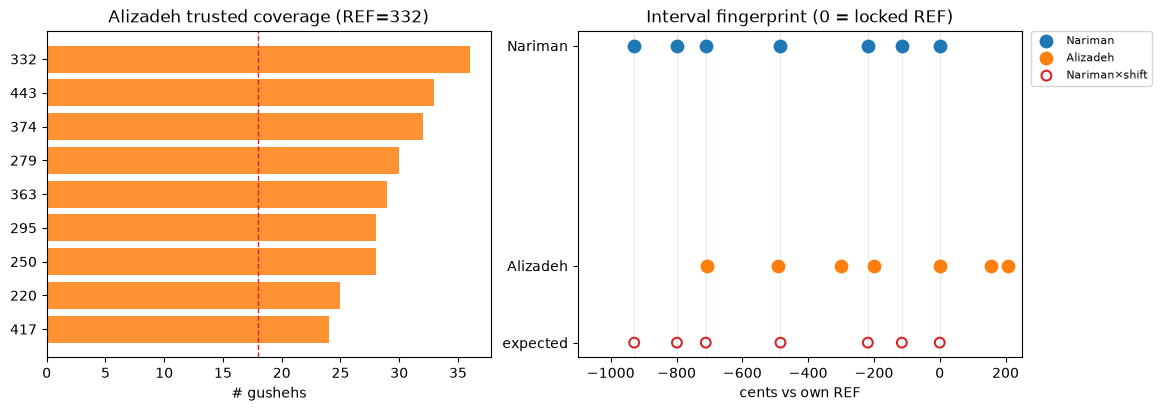


Locked ALI_REF = 331.6 Hz   (Nariman REF 265.7 + +384¢)
Note: per-strike FFT arbitration — drops HPS-only ghosts (esp. false ~250 when true≈332).


In [ ]:
from scipy.signal import find_peaks, medfilt
from audioflux.type import SpectralFilterBankScaleType, SpectralDataType, NoveltyType

# Nariman locked skeleton (§16)
NARIMAN_REF = 265.7
NARIMAN_DEGREES = [265.7, 248.6, 234.2, 200.9, 176.2, 167.5, 155.4]

CLUSTER_TOL = 40
HPS_LO, HPS_HI = 180, 900

alizadeh_album = (
    AUDIO_DIR / "YouTube Music" / "Hossein Alizadeh" / "Radif Navazi - Setar_ Mahur"
)
album_wavs = sorted(alizadeh_album.glob("*.wav"))
assert len(album_wavs) >= 35, f"need Alizadeh album, got {len(album_wavs)}"
print(f"Alizadeh tracks: {len(album_wavs)}")


def fft_f0(x, sr, fmin=160, fmax=700):
    if len(x) < 256:
        return np.nan
    w = x * np.hanning(len(x))
    Npad = int(2 ** np.ceil(np.log2(max(len(w) * 4, 1))))
    buf = np.zeros(Npad)
    buf[: len(w)] = w
    mag = np.abs(np.fft.rfft(buf))
    freqs = np.fft.rfftfreq(Npad, 1 / sr)
    band = (freqs >= fmin) & (freqs <= fmax)
    if not np.any(band):
        return np.nan
    gi = np.where(band)[0][np.argmax(mag[band])]
    if 1 <= gi < len(mag) - 1:
        a, b, c = mag[gi - 1], mag[gi], mag[gi + 1]
        ppar = 0.5 * (a - c) / (a - 2 * b + c + 1e-12)
        return float(freqs[gi] + ppar * (freqs[1] - freqs[0]))
    return float(freqs[gi])


def ac_f0(x, sr, fmin=180, fmax=550):
    seg = x - x.mean()
    if len(seg) < int(0.12 * sr):
        return np.nan
    corr = np.correlate(seg, seg, mode="full")
    corr = corr[len(corr) // 2 :]
    lo, hi = int(sr / fmax), int(sr / fmin)
    if hi <= lo + 2:
        return np.nan
    return float(sr / (lo + int(np.argmax(corr[lo:hi]))))


def cluster_fs(fs, tol=CLUSTER_TOL):
    if len(fs) == 0:
        return []
    fs = np.sort(np.asarray(fs, dtype=float))
    clusters = []
    for f in fs:
        if not clusters or abs(1200 * np.log2(f / np.median(clusters[-1]))) > tol:
            clusters.append([f])
        else:
            clusters[-1].append(f)
    out = []
    for c in sorted(clusters, key=lambda c: -len(c)):
        med = np.median(c)
        merged = False
        for o in out:
            if abs(1200 * np.log2(med / np.median(o))) <= tol:
                o.extend(c)
                merged = True
                break
        if not merged:
            out.append(c)
    return sorted(out, key=lambda c: -len(c))


def trusted_strikes(wav_path):
    """Per-strike F0: prefer FFT/AC when they disagree with HPS (setar HPS often sticks)."""
    full, sr = af.read(str(wav_path))
    if full.ndim > 1:
        full = np.mean(full, axis=0)
    full = np.ascontiguousarray(full, dtype=np.float32)

    hps = af.PitchHPS(samplate=sr, low_fre=HPS_LO, high_fre=HPS_HI, slide_length=512, harmonic_count=5)
    fre = np.asarray(hps.pitch(full), dtype=float)
    hop = 512 / sr
    times = np.arange(len(fre)) * hop
    fre[fre < 1] = np.nan
    tmp = fre.copy()
    tmp[~np.isfinite(tmp)] = np.nanmedian(fre)
    tmp = medfilt(tmp, 5)
    tmp[~np.isfinite(fre)] = np.nan
    fre_s = tmp

    bft = af.BFT(
        num=64, samplate=sr, radix2_exp=11, slide_length=1024,
        scale_type=SpectralFilterBankScaleType.MEL, data_type=SpectralDataType.POWER,
    )
    spec_db = af.utils.power_to_db(np.abs(bft.bft(full)))
    onset_obj = af.Onset(
        time_length=spec_db.shape[1], fre_length=spec_db.shape[0],
        slide_length=1024, samplate=sr, novelty_type=NoveltyType.FLUX,
    )
    _, novelty, _, _ = onset_obj.onset(spec_db)
    ohop = 1024 / sr
    peaks, _ = find_peaks(novelty, height=np.percentile(novelty, 88), distance=int(0.18 / ohop))

    rows = []
    for ot in peaks * ohop:
        seg = fre_s[(times >= ot + 0.04) & (times <= ot + 0.35)]
        seg = seg[np.isfinite(seg)]
        if seg.size < 3:
            continue
        f_hps = float(np.median(seg))
        x = full[int(ot * sr): int((ot + 0.50) * sr)]
        if len(x) < int(0.20 * sr):
            continue
        mid = x[int(0.05 * sr): int(0.35 * sr)]
        f_fft = fft_f0(mid, sr)
        f_ac = ac_f0(mid, sr)

        f_use, method = f_hps, "HPS"
        if np.isfinite(f_fft) and f_fft > 0:
            d_hf = abs(1200 * np.log2(f_hps / f_fft))
            if d_hf <= 40:
                f_use = float(np.median([f_hps, f_fft]))
                method = "HPS+FFT"
            else:
                d_af = (
                    abs(1200 * np.log2(f_ac / f_fft))
                    if np.isfinite(f_ac) and f_ac > 0
                    else np.nan
                )
                octave = abs(1200 * np.log2(f_hps / (2 * f_fft))) < 40
                if np.isfinite(d_af) and d_af <= 50:
                    f_use = float(np.median([f_fft, f_ac]))
                    method = "FFT/AC"
                elif octave:
                    f_use = f_fft
                    method = "FFT(½HPS)"
                elif np.isfinite(f_ac) and abs(1200 * np.log2(f_hps / f_ac)) <= 40:
                    f_use = float(np.median([f_hps, f_ac]))
                    method = "HPS+AC"
                else:
                    continue  # ambiguous — skip HPS ghosts
        rows.append({"f": f_use, "hps": f_hps, "fft": f_fft, "ac": f_ac, "method": method, "t": float(ot)})
    return rows


per_track = {}
all_f, all_track = [], []
method_counts = {}
for wav in album_wavs:
    label = wav.stem
    print(f"strikes: {label} ...", flush=True)
    rows = trusted_strikes(wav)
    per_track[label] = rows
    for r in rows:
        all_f.append(r["f"])
        all_track.append(label)
        method_counts[r["method"]] = method_counts.get(r["method"], 0) + 1

all_f = np.array(all_f)
all_track = np.array(all_track)
print(f"\ntrusted strikes: {len(all_f)} across {len(album_wavs)} tracks")
print("methods:", method_counts)

merged = cluster_fs(all_f)
common = []
for c in merged[:14]:
    f0 = float(np.median(c))
    mask = np.abs(1200 * np.log2(all_f / f0)) <= CLUSTER_TOL
    gset = sorted(set(all_track[mask]))
    common.append({"f0": f0, "n": int(mask.sum()), "gushehs": len(gset), "tracks": gset})

by_g = sorted(common, key=lambda d: (-d["gushehs"], -d["n"]))
n_tracks = len(album_wavs)

candidates = [d for d in by_g if d["gushehs"] >= 0.7 * n_tracks and 280 <= d["f0"] <= 400]
if not candidates:
    candidates = [d for d in by_g if 280 <= d["f0"] <= 400] or by_g[:3]
ALI_REF = max(candidates, key=lambda d: d["n"])["f0"]

print(f"\n=== Alizadeh trusted degrees (REF = {ALI_REF:.1f} Hz) ===")
print(f"{'rank':>4} {'F0':>7} {'n':>5} {'gushehs':>7} {'pctG':>5}  {'¢ vs REF':>8}")
print("-" * 60)
for rank, d in enumerate(sorted(common, key=lambda d: -d["n"]), 1):
    d["cents"] = 1200 * np.log2(d["f0"] / ALI_REF)
    mark = "★" if d["gushehs"] >= 0.5 * n_tracks else " "
    print(f"{rank:4d} {d['f0']:7.1f} {d['n']:5d} {d['gushehs']:7d} {100*d['gushehs']/n_tracks:4.0f}%  {d['cents']:+8.1f}  {mark}")

print("\n=== Ranked by gusheh coverage ===")
for d in by_g:
    d["cents"] = 1200 * np.log2(d["f0"] / ALI_REF)
    mark = "★" if d["gushehs"] >= int(0.5 * n_tracks) else " "
    print(f"{mark} {d['f0']:7.1f} Hz   {d['gushehs']:2d}/{n_tracks}   n={d['n']:4d}   {d['cents']:+7.1f}¢")

shift_cents = 1200 * np.log2(ALI_REF / NARIMAN_REF)
print(f"\n=== Nariman ↔ Alizadeh transposition ===")
print(f"Nariman REF {NARIMAN_REF:.1f} → Alizadeh REF {ALI_REF:.1f}   shift = {shift_cents:+.1f}¢  (×{ALI_REF/NARIMAN_REF:.4f})")

ali_star = [d for d in by_g if d["gushehs"] >= int(0.35 * n_tracks)]
print(f"\n{'Nariman':>10} {'¢N':>7} │ {'expect':>8} {'Alizadeh':>10} {'¢A':>7} │ {'Δ¢':>6}  match  (n@expect)")
print("-" * 78)
for nf in NARIMAN_DEGREES:
    nc = 1200 * np.log2(nf / NARIMAN_REF)
    expect = nf * (ALI_REF / NARIMAN_REF)
    n_at = int(np.sum(np.abs(1200 * np.log2(all_f / expect)) <= CLUSTER_TOL))
    g_at = len({tr for tr, f in zip(all_track, all_f) if abs(1200 * np.log2(f / expect)) <= CLUSTER_TOL})
    if ali_star:
        best = min(ali_star, key=lambda d: abs(1200 * np.log2(d["f0"] / expect)))
        acents = best["cents"]
        dc = acents - nc
        ok = "✓" if abs(dc) <= 40 else ("~" if abs(dc) <= 80 else "✗")
        print(
            f"{nf:10.1f} {nc:+7.1f} │ {expect:8.1f} {best['f0']:10.1f} {acents:+7.1f} │ {dc:+6.1f}  {ok}   "
            f"n={n_at} in {g_at}/{n_tracks}"
        )

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4), constrained_layout=True)
ax = axes[0]
degs = [d for d in by_g if d["gushehs"] >= int(0.4 * n_tracks)][:10]
ax.barh([f"{d['f0']:.0f}" for d in degs][::-1], [d["gushehs"] for d in degs][::-1], color="C1", alpha=0.85)
ax.axvline(n_tracks / 2, color="C3", ls="--", lw=1)
ax.set_xlabel("# gushehs")
ax.set_title(f"Alizadeh trusted coverage (REF={ALI_REF:.0f})")

ax = axes[1]
n_cents = [1200 * np.log2(f / NARIMAN_REF) for f in NARIMAN_DEGREES]
a_cents = [d["cents"] for d in degs]
ax.scatter(n_cents, [1] * len(n_cents), s=80, color="C0", label="Nariman", zorder=3)
ax.scatter(a_cents, [0] * len(a_cents), s=80, color="C1", label="Alizadeh", zorder=3)
ax.scatter(n_cents, [-0.35] * len(n_cents), s=50, facecolors="none", edgecolors="C3",
           linewidths=1.5, label="Nariman×shift", zorder=3)
for c in n_cents:
    ax.axvline(c, color="C0", alpha=0.12, lw=1)
ax.set_yticks([-0.35, 0, 1])
ax.set_yticklabels(["expected", "Alizadeh", "Nariman"])
ax.set_xlabel("cents vs own REF")
ax.set_title("Interval fingerprint (0 = locked REF)")
ax.set_xlim(-1100, 250)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
plt.show()

print(f"\nLocked ALI_REF = {ALI_REF:.1f} Hz   (Nariman REF {NARIMAN_REF} + {shift_cents:+.0f}¢)")
print("Note: per-strike FFT arbitration — drops HPS-only ghosts (esp. false ~250 when true≈332).")



## 17b. Analysis cache

Heavy steps (HPS strikes, sliding-window Do, filters) live under `analysis/` as `.npz` / `.json`.

| artifact | meaning |
|---|---|
| `strikes_*.npz` | trusted onset F0s per album |
| `lotfi_local_do.npz` / `ebadi_local_do.npz` / `saba_local_do.npz` | sliding-window Do |
| `strikes_shahnazi.npz` / `shahnazi_filter.json` | Shahnazi Mahur |
| `*_filter.json` | kept/skipped track lists |
| `consensus_template.json` | drift-adjusted consensus degrees |

**Run All** only *loads* these. Set `FORCE_REBUILD_CONSENSUS = True` (setup cell) to recompute the consensus JSON from strikes (still no audio re-HPS). Re-extracting strikes from wavs is intentional/manual (`analysis/latch_overnight.py` etc.).


In [ ]:
import json
import importlib.util

spec = importlib.util.spec_from_file_location(
    "rebuild_consensus_from_cache",
    ANALYSIS_DIR / "rebuild_consensus_from_cache.py",
)
rebuild_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(rebuild_mod)

print("analysis cache:")
for name, ok, sz in rebuild_mod.cache_status():
    mark = "✓" if ok else "✗"
    if ok:
        print(f"  {mark} {name:35} {sz/1e3:7.1f} KB")
    else:
        print(f"  {mark} {name}")

consensus_path = ANALYSIS_DIR / "consensus_template.json"
if FORCE_REBUILD_CONSENSUS or not consensus_path.exists():
    print("\nrebuilding consensus from strikes_*.npz …")
    CONSENSUS = rebuild_mod.rebuild(write=True)
    print("wrote", consensus_path)
else:
    CONSENSUS = json.loads(consensus_path.read_text())
    print(
        f"\nloaded cached consensus ({len(CONSENSUS['albums'])} artists, "
        f"{len(CONSENSUS['slots'])} slots) ← {consensus_path.name}"
    )


## 18. Thirteen-way latch — + Karimi vocals; Kasaei = setar

**Karimi** [*Avaz Course: Vocal Radif Vol. 3*](https://www.youtube.com/playlist?list=OLAK5uy_m4dCFMnjQWeftOYFJ5gTkk7flPWpkbA4w) ([Shekaste](https://www.youtube.com/watch?v=5PYPwl32j1Y)):
- **Mahur only** (tracks 11–30); skip Chahargah / Rast-Panjgah
- Do ≈ **201 Hz**; La ≈ **−306¢** (near forced 27/32)

**Kasaei radif** relabeled **setar** (not ney). Solo ney stays dropped.

Degree match is **octave-folded**: Sol↓ evidence also fills Sol↑ (and Fa / La / Re pairs). **Filled** = heard in that octave; **open circle** = filled only via the other octave.

Guide lines: **½× / 2×**, **2/3·3/4·4/3·3/2** (Fa/Sol), **9/8 · 10/9** (Re), **27/32 · 5/6** (La). X ticks every **100¢**.

**Focus — La.** Fretted: La ≈ **9/8 × 3/4 = 27/32 (−294¢)** by shared frets. Consensus ≈ **−300¢**.

**13 sources.** Artifacts: `strikes_karimi.npz`, `karimi_filter.json`.


Saba Do≈376.8 Hz  σ=6.3¢  n=2206
Kasaei radif (setar) Do≈370.8 Hz
Karimi voice Do≈200.5 Hz  La≈-305.6¢

artist               Do     σ¢      n
karimi           200.53   20.6   3999
saba             376.78    6.3   2206
kasaei_radif     370.76   14.0   4829
shahnazi         385.28    3.9   2165
ebadi            253.02    6.4   1471
neydavud         266.34   22.9   3102
forutan          225.69    8.6   3559
lotfi            326.39    3.3   2665
lotfi_mahur      318.73    2.9   2488
borumand         327.04   11.7   5564
alizadeh         332.01    4.7   6191
nariman          265.32    2.3   5954
shekarchi        443.00    9.3   5451

La focus: consensus La=-299.6¢  (13/13)  La↑=+900.4¢
  theory: 5/6=-315.6¢  ET m3=-300.0¢  |  5/3=+884.4¢  ET M6=900.0¢
  Re guides: 9/8=+203.9¢  10/9=+182.4¢

Consensus:
  Re↓    -998.6¢  (13/13)
  Mi↓    -915.2¢  (11/13)
  Fa     -703.5¢  (13/13)
  Sol    -499.5¢  (13/13)
  La     -299.6¢  (13/13)
  Si     -209.4¢  (13/13)
  Siᵏ     -99.1¢  (8/13)
  Do       

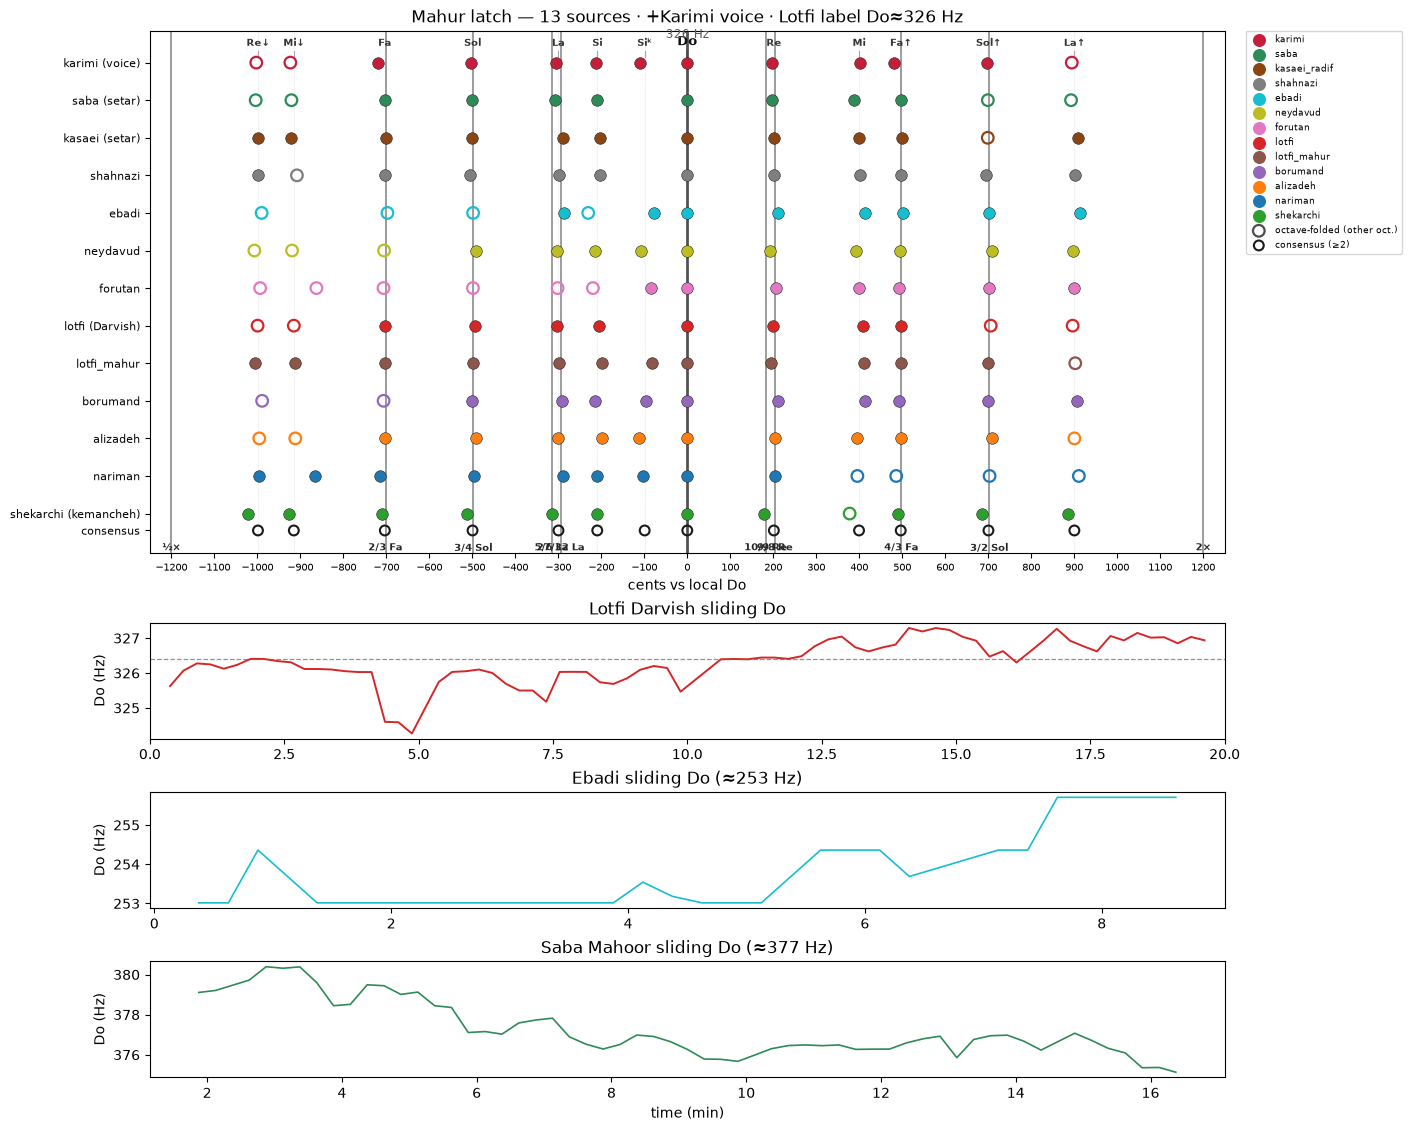

saved: /Users/ed/Developer/dastgaah/analysis/latch_fingerprint_final.png
ratio lines ¢: [('½×', -1200.0), ('2/3 Fa', -702.0), ('3/4 Sol', -498.0), ('5/6 La', -315.6), ('27/32 La', -294.1), ('10/9 Re', 182.4), ('9/8 Re', 203.9), ('4/3 Fa', 498.0), ('3/2 Sol', 702.0), ('2×', 1200.0)]


In [234]:
# Twelve-way latch: + Saba; no Kasaei solo; pure-ratio guides
from pathlib import Path
import json
import math
import numpy as np
import matplotlib.pyplot as plt

# Always reload from disk (kernel CONSENSUS can be stale after adding artists)
data = json.loads((ANALYSIS_DIR / "consensus_template.json").read_text())
CONSENSUS = data
local_path = ANALYSIS_DIR / "lotfi_local_do.npz"
ebadi_path = ANALYSIS_DIR / "ebadi_local_do.npz"
saba_path = ANALYSIS_DIR / "saba_local_do.npz"
local = np.load(local_path) if local_path.exists() else None
ebadi_do = np.load(ebadi_path) if ebadi_path.exists() else None
saba_do = np.load(saba_path) if saba_path.exists() else None
slots_all = sorted(data["slots"], key=lambda s: s["cents"])
LOTFI_DO = data["do_stats"]["lotfi"]["median_do"]

order = ["karimi", "saba", "kasaei_radif", "shahnazi", "ebadi", "neydavud", "forutan",
         "lotfi", "lotfi_mahur", "borumand", "alizadeh", "nariman", "shekarchi"]
colors = {
    "karimi": "#C41E3A", "saba": "#2E8B57", "kasaei_radif": "#8B4513", "shahnazi": "C7",
    "ebadi": "C9", "neydavud": "C8", "forutan": "C6", "lotfi": "C3", "lotfi_mahur": "C5",
    "borumand": "C4", "alizadeh": "C1", "nariman": "C0", "shekarchi": "C2",
}
ys = {n: i for i, n in enumerate(reversed(order))}
ylabels = ["consensus"] + list(reversed([
    "karimi (voice)", "saba (setar)", "kasaei (setar)", "shahnazi", "ebadi", "neydavud", "forutan",
    "lotfi (Darvish)", "lotfi_mahur", "borumand", "alizadeh", "nariman",
    "shekarchi (kemancheh)",
]))

print(f"Saba Do≈{data['do_stats']['saba']['median_do']:.1f} Hz  "
      f"σ={data['do_stats']['saba']['std_cents']:.1f}¢  "
      f"n={data['do_stats']['saba']['n_strikes']}")
print(f"Kasaei radif (setar) Do≈{data['do_stats']['kasaei_radif']['median_do']:.1f} Hz")
print(f"Karimi voice Do≈{data['do_stats']['karimi']['median_do']:.1f} Hz  La≈{next(d['matched_cents'] for d in data['albums']['karimi']['details'] if d['label']=='La'):+.1f}¢")

print(f"\n{'artist':14} {'Do':>8} {'σ¢':>6} {'n':>6}")
for name in order:
    s = data["do_stats"][name]
    print(f"{name:14} {s['median_do']:8.2f} {s['std_cents']:6.1f} {s['n_strikes']:6}")

n_src = len(order)

# La focus
la = next(s for s in slots_all if s["name"] == "La")
la_up = next((s for s in slots_all if s["name"] == "La↑"), None)
print(f"\nLa focus: consensus La={la['cents']:+.1f}¢  ({la['n_artists']}/{n_src})"
      + (f"  La↑={la_up['cents']:+.1f}¢" if la_up else ""))
print(f"  theory: 5/6={1200*math.log2(5/6):+.1f}¢  ET m3={-300.0:.1f}¢  |  "
      f"5/3={1200*math.log2(5/3):+.1f}¢  ET M6={900.0:.1f}¢")
print(f"  Re guides: 9/8={1200*math.log2(9/8):+.1f}¢  10/9={1200*math.log2(10/9):+.1f}¢")

print("\nConsensus:")
for s in slots_all:
    print(f"  {s['name']:5} {s['cents']:+7.1f}¢  ({s['n_artists']}/{n_src})")

# pure frequency ratios vs Do
#   ½× / 2× = octaves
#   3/4 (−498¢) = Sol↓  ·  3/2 (+702¢) = Sol↑
#   2/3 (−702¢) = Fa↓   ·  4/3 (+498¢) = Fa↑
RATIO_LINES = [
    (0.5,  "½×",           1200 * math.log2(0.5)),
    (2/3,  "2/3 Fa",       1200 * math.log2(2/3)),
    (0.75, "3/4 Sol",      1200 * math.log2(0.75)),
    (5/6,  "5/6 La",       1200 * math.log2(5/6)),
    (27/32,"27/32 La",     1200 * math.log2(27/32)),
    (10/9, "10/9 Re",      1200 * math.log2(10/9)),
    (9/8,  "9/8 Re",       1200 * math.log2(9/8)),
    (4/3,  "4/3 Fa",       1200 * math.log2(4/3)),
    (1.5,  "3/2 Sol",      1200 * math.log2(1.5)),
    (2.0,  "2×",           1200 * math.log2(2.0)),
]

extras = [x for x in (local, ebadi_do, saba_do) if x is not None]
n_extra = len(extras)
fig, axes = plt.subplots(
    1 + n_extra, 1,
    figsize=(14.0, 7.0 + 1.4 * n_extra),
    constrained_layout=True,
    gridspec_kw={"height_ratios": [4.5] + [1.0] * n_extra} if n_extra else None,
)
if n_extra == 0:
    axes = [axes]
ax = axes[0]
tmpl = [s["cents"] for s in slots_all]
top_y = max(ys.values())

# ratio guides (solid) — behind everything
for ratio, lab, c_off in RATIO_LINES:
    ax.axvline(c_off, color="0.15", ls="-", lw=1.15, alpha=0.55, zorder=0)
    ax.text(c_off, -0.78, lab, ha="center", va="top", fontsize=7, color="0.15",
            fontweight="600")

# filled = heard in that octave; open = octave-folded from the other octave
for name in order:
    for d in data["albums"][name]["details"]:
        if not (d["ok"] and d["matched_cents"] is not None):
            continue
        native = d.get("native", True)
        if native:
            ax.scatter([d["matched_cents"]], [ys[name]], s=70, color=colors[name],
                       zorder=3, edgecolors="0.15", linewidths=0.4)
        else:
            ax.scatter([d["matched_cents"]], [ys[name]], s=70, facecolors="none",
                       edgecolors=colors[name], linewidths=1.6, zorder=3)
for name in order:
    ax.scatter([], [], s=70, color=colors[name], label=name)
ax.scatter([], [], s=70, facecolors="none", edgecolors="0.3", linewidths=1.6,
           label="octave-folded (other oct.)")
ax.scatter(tmpl, [-0.45] * len(tmpl), s=50, facecolors="none", edgecolors="0.1",
           linewidths=1.5, label="consensus (≥2)", zorder=2)
for c in tmpl:
    ax.axvline(c, color="0.55", alpha=0.10, lw=0.8, zorder=0)
ax.axvline(0.0, color="0.05", alpha=0.7, lw=2.0, zorder=1)  # 1× = Do

for s in slots_all:
    c, deg = s["cents"], s["name"]
    is_do = deg == "Do"
    ax.plot([c, c], [top_y + 0.15, top_y + 0.32], color="0.3" if is_do else "0.65",
            lw=1.3 if is_do else 0.8, zorder=1)
    ax.text(c, top_y + 0.38, deg, ha="center", va="bottom",
            fontsize=9.5 if is_do else 7.5,
            fontweight="bold" if is_do else "600",
            color="0.05" if is_do else "0.2")
    if is_do:
        ax.text(c, top_y + 0.58, f"{LOTFI_DO:.0f} Hz", ha="center", va="bottom",
                fontsize=8.5, color="0.35")

ax.set_yticks([-0.45] + list(range(len(order))))
ax.set_yticklabels(ylabels, fontsize=8)
ax.set_xlabel("cents vs local Do")
ax.set_title(f"Mahur latch — {n_src} sources · +Karimi voice · Lotfi label Do≈{LOTFI_DO:.0f} Hz")
ax.set_xlim(-1250, 1250)
ax.set_xticks(np.arange(-1200, 1201, 100))
ax.tick_params(axis="x", labelsize=7.5)
ax.set_ylim(-1.05, top_y + 0.85)
ax.legend(fontsize=6.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)

ai = 1
if local is not None:
    axes[ai].plot(local["t_win"] / 60.0, local["do_hz"], color="C3", lw=1.4)
    axes[ai].axhline(LOTFI_DO, color="0.4", ls="--", lw=0.9, alpha=0.7)
    axes[ai].set_ylabel("Do (Hz)")
    axes[ai].set_title("Lotfi Darvish sliding Do")
    axes[ai].set_xlim(0, 20)
    ai += 1
if ebadi_do is not None:
    axes[ai].plot(ebadi_do["t_win"]/60.0, ebadi_do["do_hz"], color="C9", lw=1.2)
    axes[ai].set_ylabel("Do (Hz)")
    axes[ai].set_title(f"Ebadi sliding Do (≈{data['do_stats']['ebadi']['median_do']:.0f} Hz)")
    ai += 1
if saba_do is not None:
    axes[ai].plot(saba_do["t_win"]/60.0, saba_do["do_hz"], color="#2E8B57", lw=1.2)
    axes[ai].set_xlabel("time (min)")
    axes[ai].set_ylabel("Do (Hz)")
    axes[ai].set_title(f"Saba Mahoor sliding Do (≈{data['do_stats']['saba']['median_do']:.0f} Hz)")

plt.show()
fig.savefig(ANALYSIS_DIR / "latch_fingerprint_final.png", dpi=170)
print("saved:", ANALYSIS_DIR / "latch_fingerprint_final.png")
print("ratio lines ¢:", [(lab, round(c, 1)) for _, lab, c in RATIO_LINES])
